This may be absolute becuase our id's are not revised between the queired date

In [1]:
#!/usr/bin/env python

# make sure to install these packages before running:
# pip install pandas
# pip install sodapy
import pandas as pd
from sodapy import Socrata
import numpy as np

# Unauthenticated client only works with public data sets. Note 'None'
# in place of application token, and no username or password:
client = Socrata("data.transportation.gov", None)

client = Socrata( "data.transportation.gov",
                     '1hCte9vYL7IpE7pFTGR1cbn8y',
                     username="hugo.baca4515@coyote.csusb.edu",
                     password="Hugobacaalex1!" )

# First 2000 results, returned as JSON from API / converted to Python list of
# dictionaries by sodapy.

results = client.get("m2f8-22s6" , where="revisiondate between '2023-01-01' and '2023-10-15'")


# Convert to pandas DataFrame
results_df_2023 = pd.DataFrame.from_records(results)

In [2]:
results_df_2023.columns.values.tolist()

['revisiondate',
 'railroadcode',
 'railroadname',
 'reportingagencytypecode',
 'reportingagencytype',
 'reasoncode',
 'reasondescription',
 'crossingid',
 'crossingidsuffix',
 'reportingagencycode',
 'reportingagencyname',
 'statecode',
 'statename',
 'countycode',
 'countyname',
 'innearcode',
 'innear',
 'citycode',
 'cityname',
 'citydescription',
 'street',
 'highwayname',
 'separatetrack',
 'sametrack',
 'railroaddivision',
 'railroadsubdivision',
 'railroadmilepostnumber',
 'timetablestation',
 'parentrailroadcode',
 'crossingownercode',
 'crossingtypecode',
 'crossingtype',
 'crossingpurposecode',
 'crossingpurpose',
 'crossingpositioncode',
 'crossingposition',
 'publicaccess',
 'typeoftrainserviceids',
 'typeoftrainserviceid1',
 'typeoftrainservice1',
 'ltpassengertrainperday',
 'numberpassengertrainperday',
 'developmenttypecode',
 'developmenttype',
 'adjacentcrossing',
 'whistlebancode',
 'whistleban',
 'hsrcorridorid',
 'latitude',
 'longitude',
 'latlongsourcecode',
 'la

In [3]:
results_df_2023.head()

,revisiondate,railroadcode,railroadname,reportingagencytypecode,reportingagencytype,reasoncode,reasondescription,crossingid,crossingidsuffix,reportingagencycode,...,advancewarning5,advancewarningtext5,advancewarning6,advancewarningtext6,ccmqzid,separatetrackrailroad2,crossingsurfaceid3,crossingsurfacedescription3,advancewarning7,advancewarningtext7
0,2023-01-02T00:00:00.000,UP,Union Pacific Railroad Company,1,Railroad,20,Date Change Only,253549F,UP,UP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-02T00:00:00.000,UP,Union Pacific Railroad Company,1,Railroad,20,Date Change Only,448211M,UP,UP,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2023-01-03T00:00:00.000,DME,"Dakota, Minnesota & Eastern Railroad",1,Railroad,14,Change in Data,375716P,DME,DME,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-03T00:00:00.000,DME,"Dakota, Minnesota & Eastern Railroad",1,Railroad,14,Change in Data,375594M,DME,DME,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2023-01-03T00:00:00.000,DME,"Dakota, Minnesota & Eastern Railroad",1,Railroad,14,Change in Data,375748V,DME,DME,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
results_df_2023.columns = results_df_2023.columns.str.strip()


In [5]:
columns_to_drop = [
    'railroadcode', 'maintenancerailroadcode', 'maintenancerailroadname',
    'neareststation', 'subdivision', 'reporting_parent_railroad_code',
    'maintenance_parent_railroad_name', 'maintenance_railroad_holding_company',
    'url', 'maintenance_parent_railroad_code', 'maintenance_railroad_smt_grouping',
    'reporting_railroad_holding_company', 'reporting_railroad_smt_grouping',
    'reporting_parent_railroad_name'
]

columns_to_drop = [col for col in columns_to_drop if col in results_df_2023.columns]

results_df_2023.drop(columns=columns_to_drop, inplace=True)


So we should clean up the result data fram

In [6]:
#Explore for NA's, missing data, and redunnacy

isnaValues = results_df_2023.isna()
print(isnaValues)

# Check for NA values
missing_values = results_df_2023.isna().sum()

#check for null values
missing_data = results_df_2023.isnull().sum()
print(missing_data)

# Check for missing data
for column in results_df_2023.columns:
    if missing_values[column] > 0:
        print(f"The column {column} has {missing_values[column]} missing values.")

# Check for redundancy
for column in results_df_2023.columns:
    if results_df_2023[column].duplicated().sum() > 0:
        print(f"The column {column} has {results_df_2023[column].duplicated().sum()} duplicate values.")

#lets try to clean up raw data

# Calculate the percentage of missing values in each column
missing_values = results_df_2023.isna().mean()

# Drop columns with more than 30% missing values
drop_list = [column for column in missing_values.index if missing_values[column] > 0.3]

# Drop the columns
crossing_inventory_data_clean = results_df_2023.drop(columns=drop_list)


# Check the shape of the raw data
print(f"The Raw Data Frame has {results_df_2023.shape[0]} rows and {results_df_2023.shape[1]} columns.")
print(f"\n The Raw Data Frame has {len(results_df_2023.columns)} labels.")
print(f"\n The Clean Data Frame now has {len(crossing_inventory_data_clean.columns)} labels.")
print("\n Count of labels dropped: \n", len(results_df_2023.columns) - len(crossing_inventory_data_clean.columns) )
print("\n Deleted Labels: \n", drop_list)
print("\n Cleaned Data Labels: \n", crossing_inventory_data_clean.columns.values)

     revisiondate  railroadname  reportingagencytypecode  reportingagencytype  \
0           False         False                    False                False   
1           False         False                    False                False   
2           False         False                    False                False   
3           False         False                    False                False   
4           False         False                    False                False   
..            ...           ...                      ...                  ...   
995         False         False                    False                False   
996         False         False                    False                False   
997         False         False                    False                False   
998         False         False                    False                False   
999         False         False                    False                False   

     reasoncode  reasondesc

In [7]:

from tabulate import tabulate
print(tabulate(crossing_inventory_data_clean, headers = 'keys', tablefmt = 'psql'))

+-----+-------------------------+----------------------------------------------+---------------------------+-----------------------+--------------+--------------------------------+--------------+--------------------+-----------------------+----------------------------------------------+-------------+----------------+--------------+------------------+--------------+----------+------------+-----------------+------------------------------------------------------------+----------------------------------+---------------------------+-----------------+-------------+---------------------+-----------------------+--------------------------+--------------------+----------------------+---------------------+--------------------+----------------+-----------------------+-------------------+------------------------+--------------------+-------------------------+-------------------------+-----------------------+--------------------------+------------------------------+-----------------------+----------

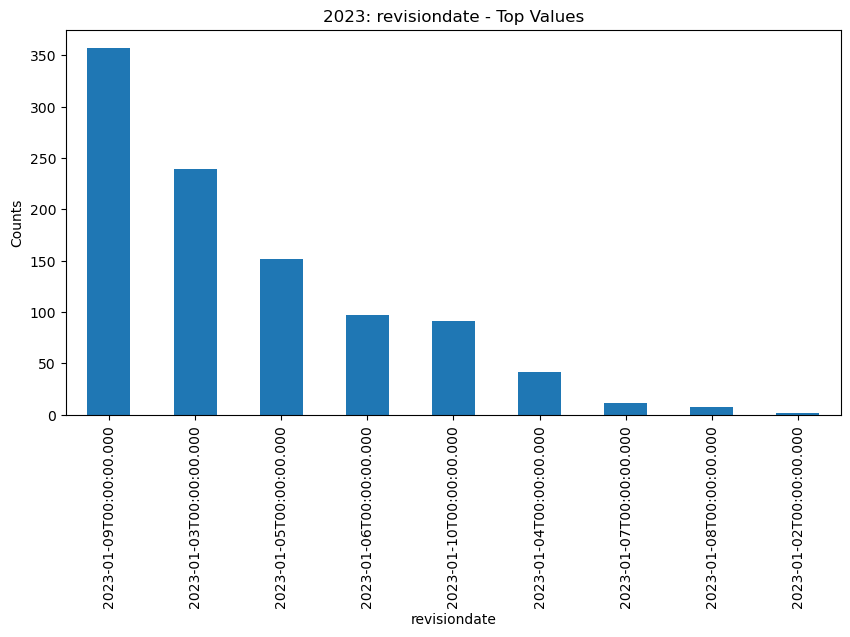

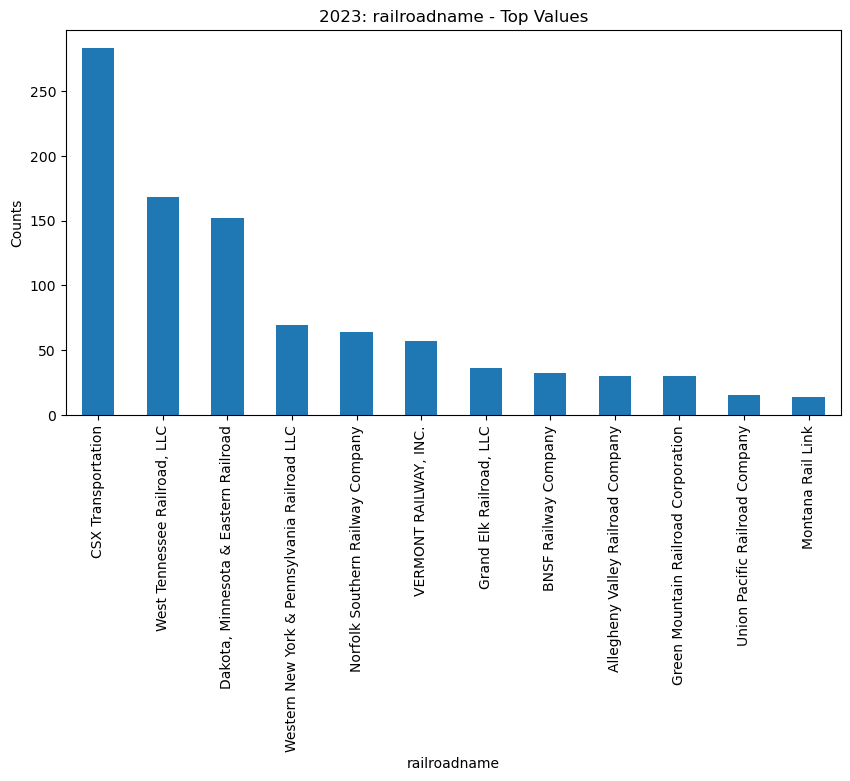

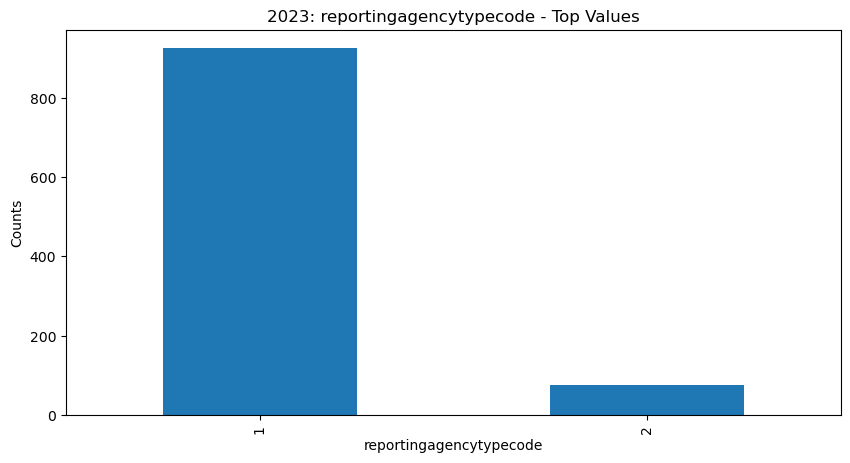

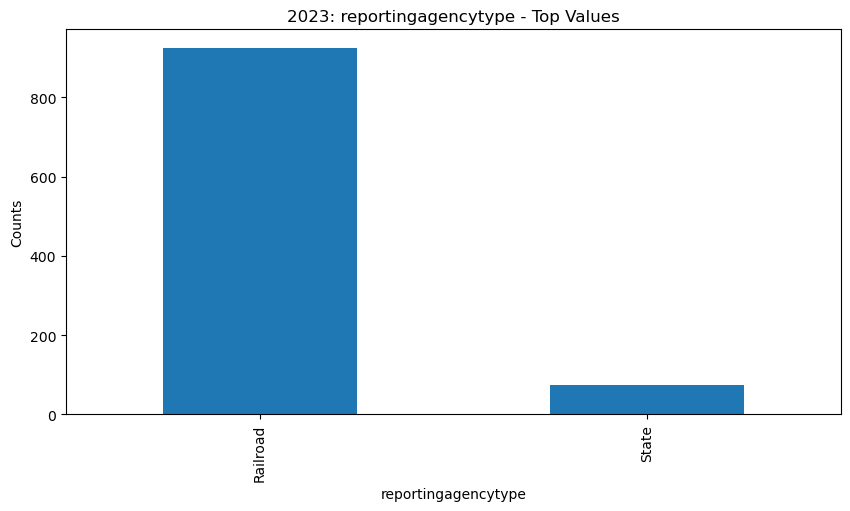

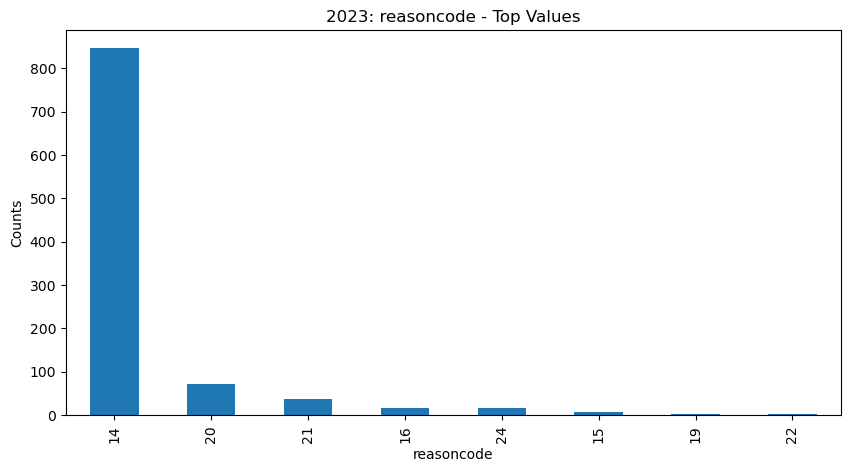

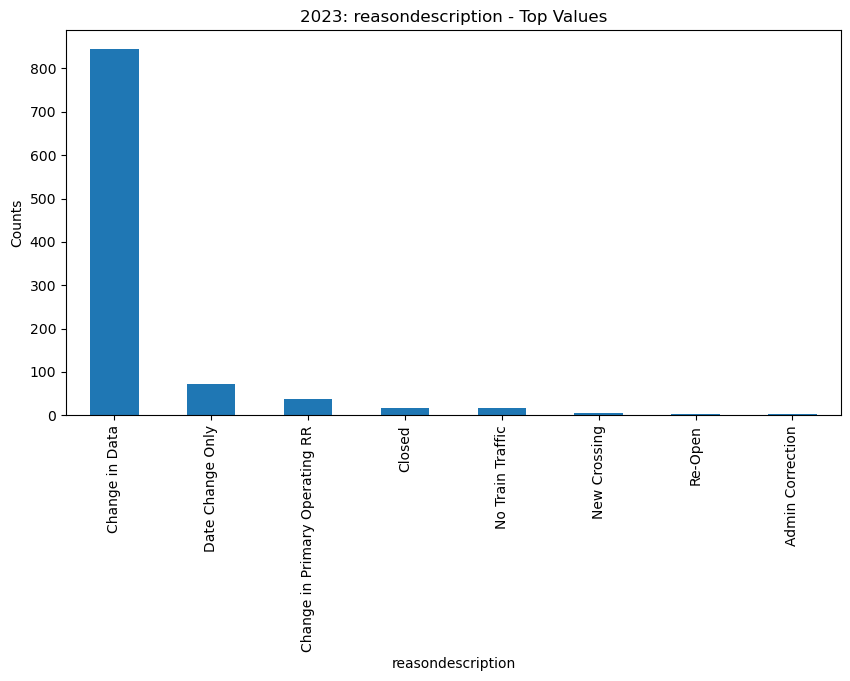

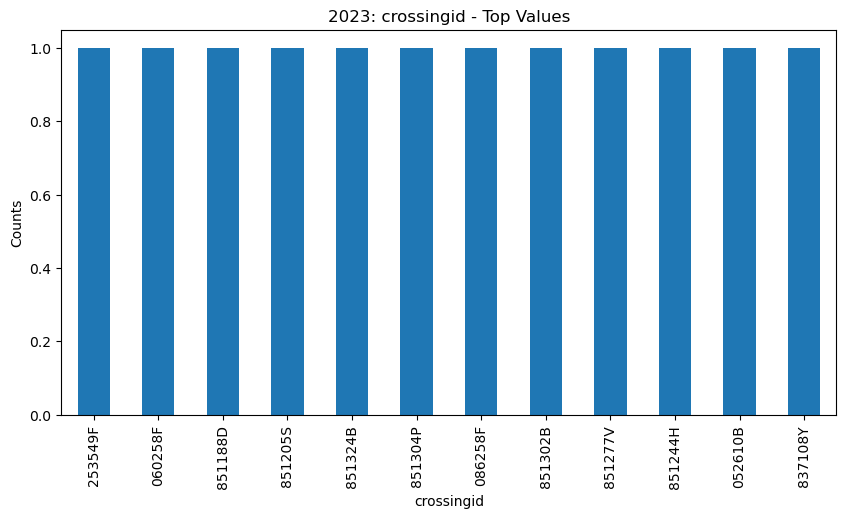

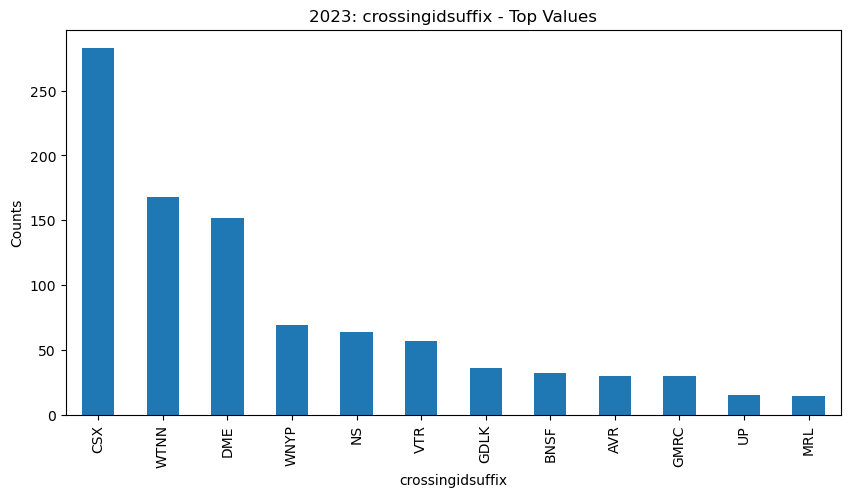

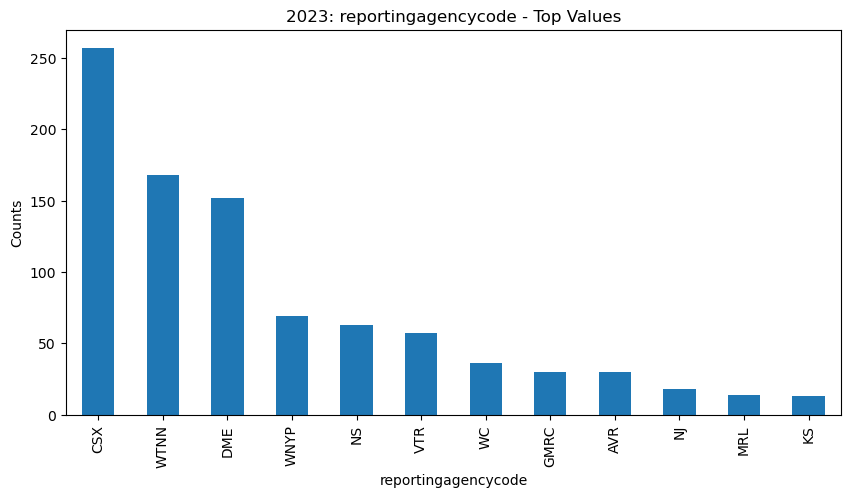

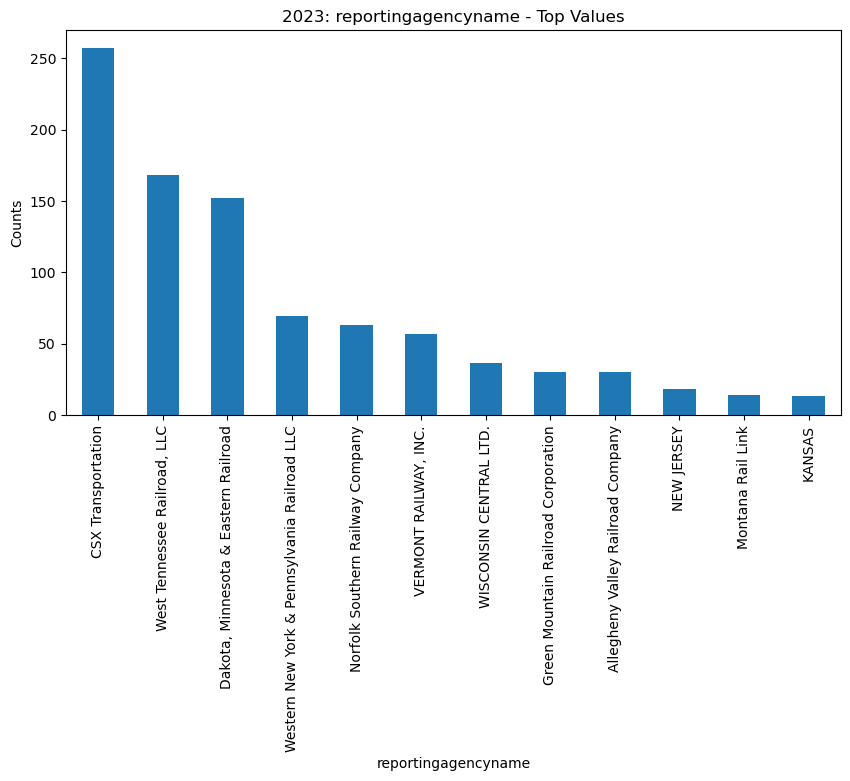

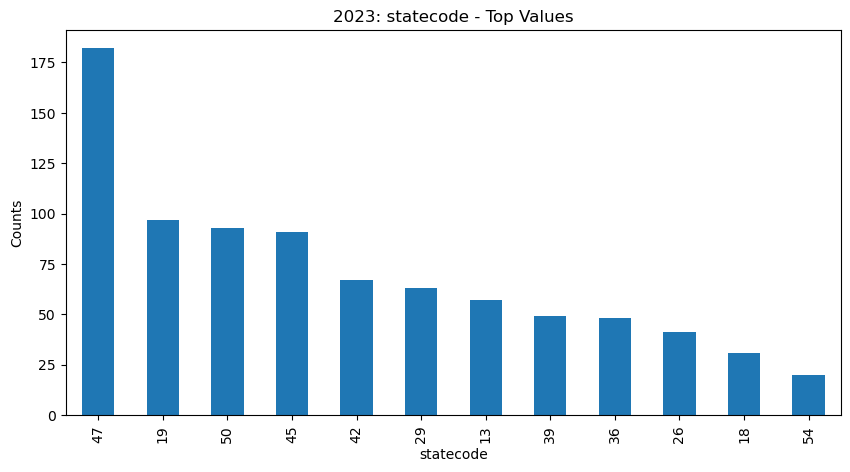

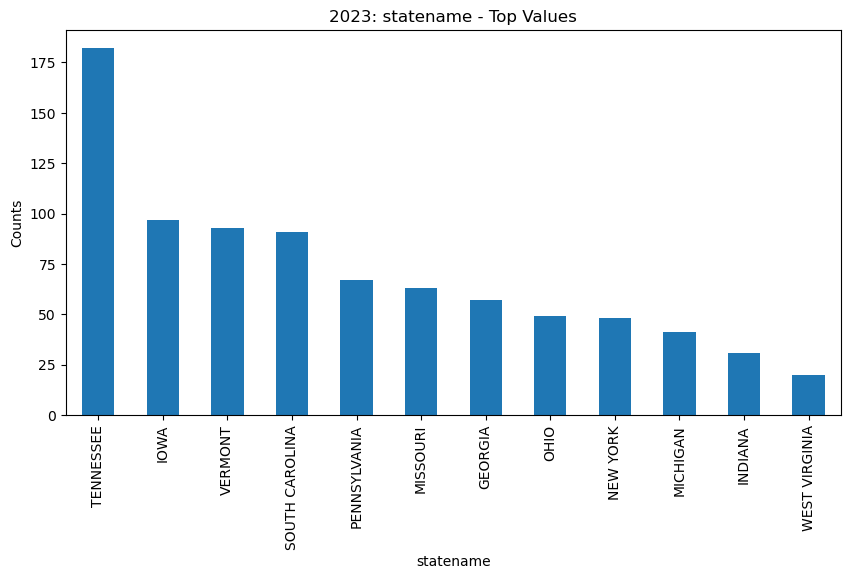

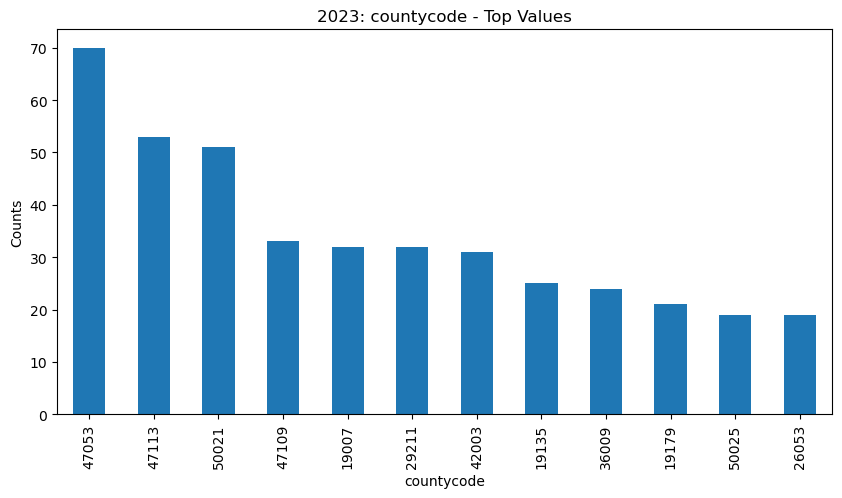

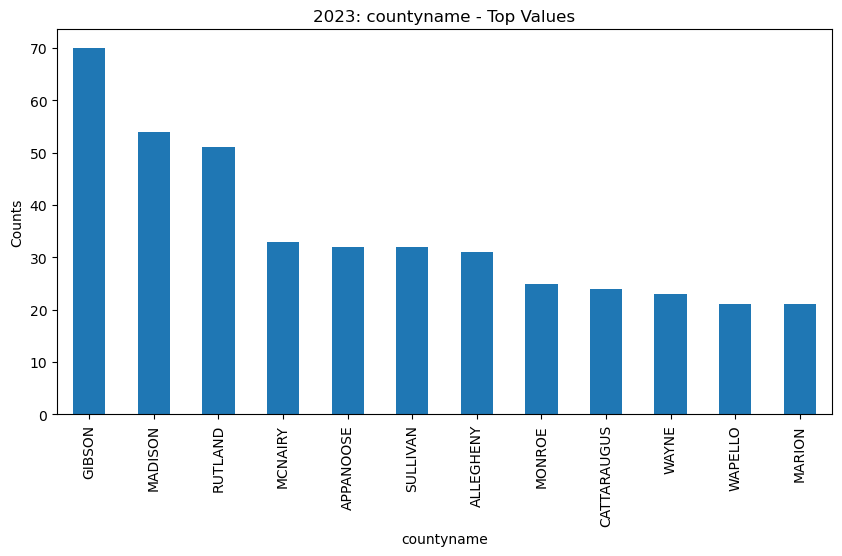

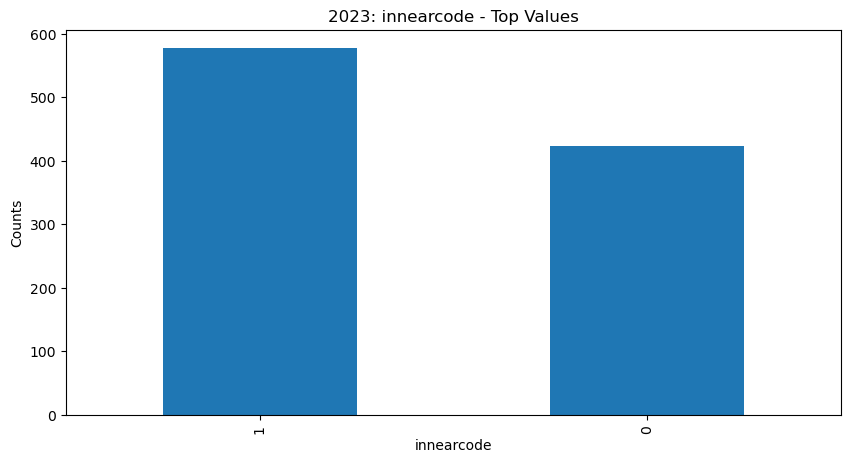

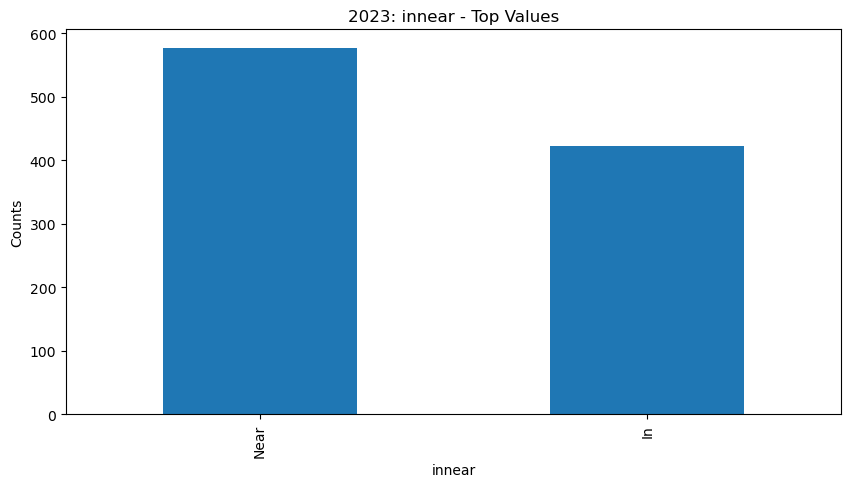

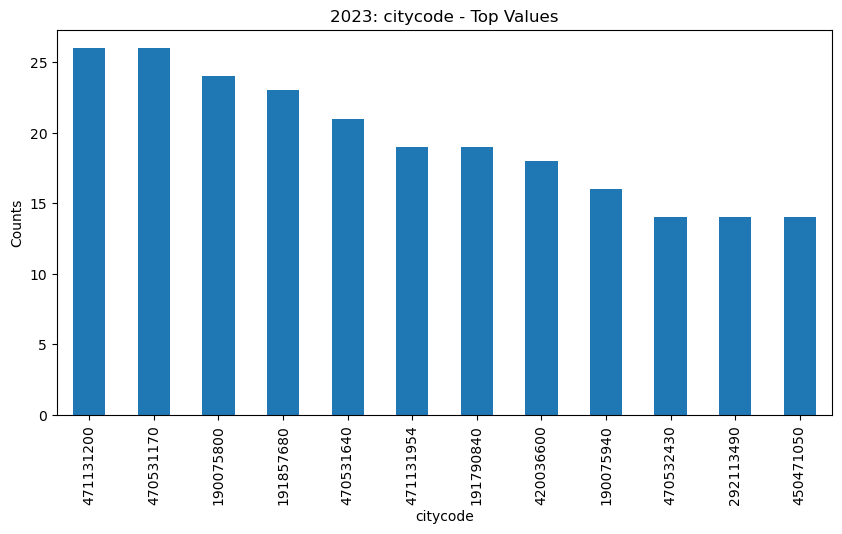

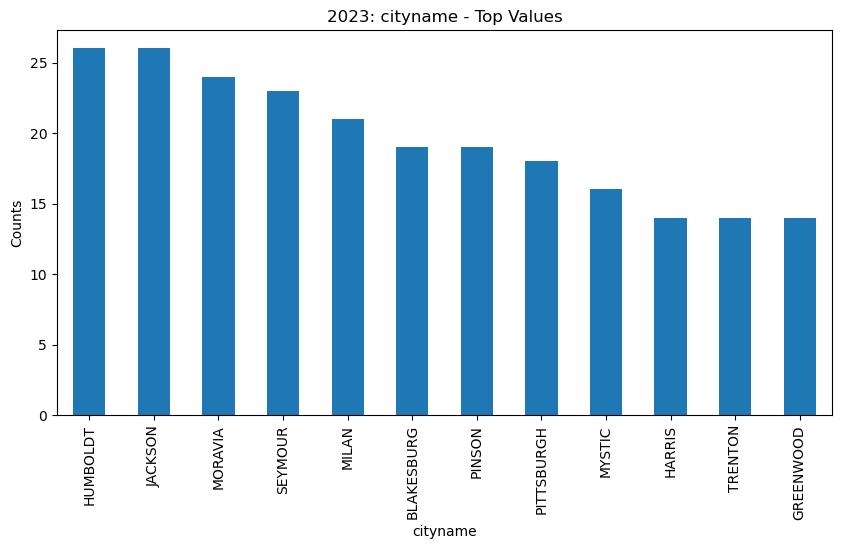

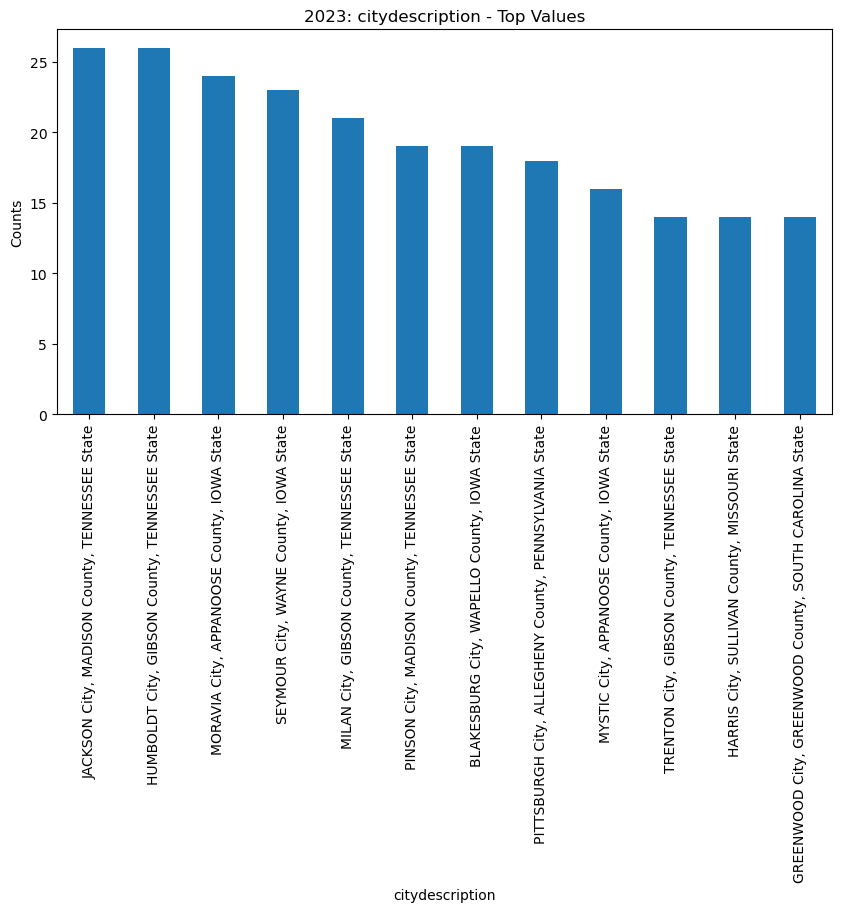

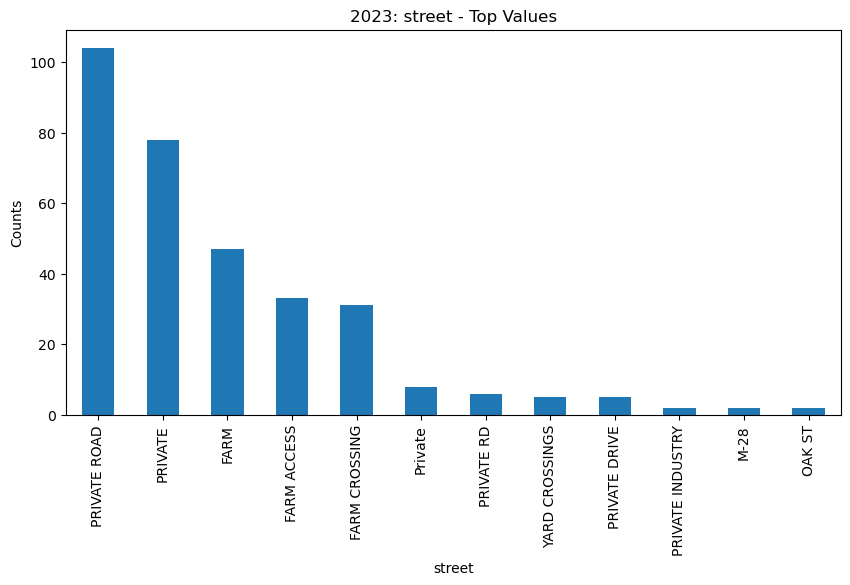

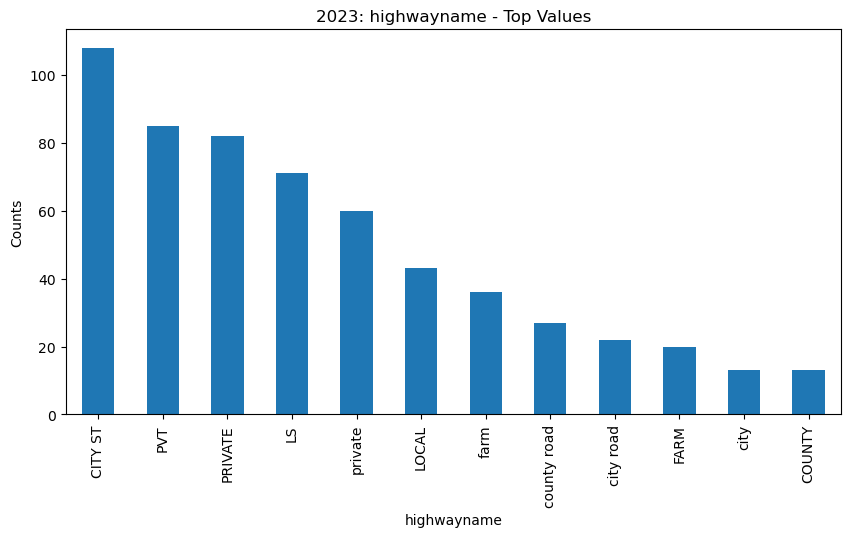

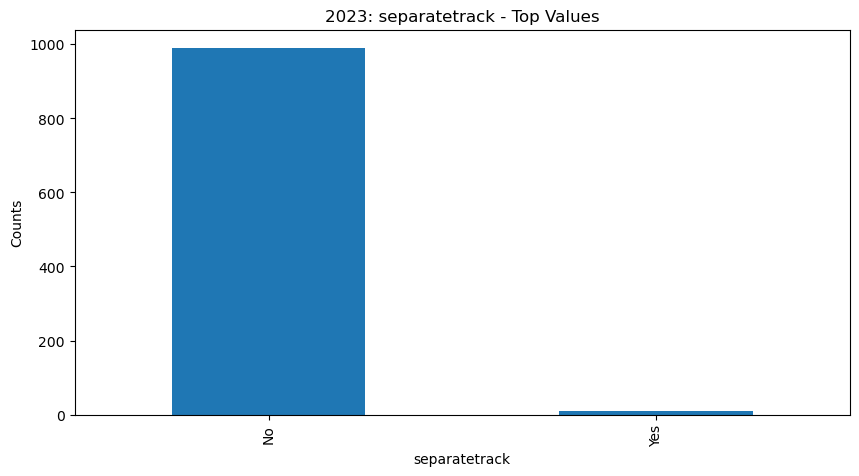

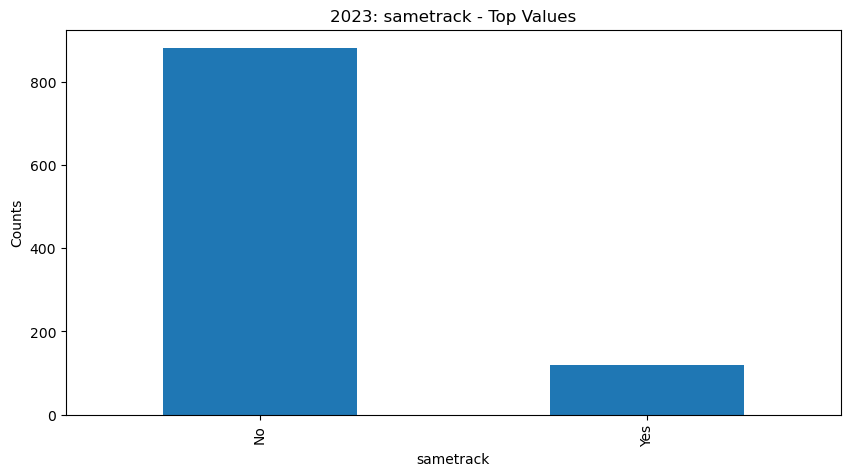

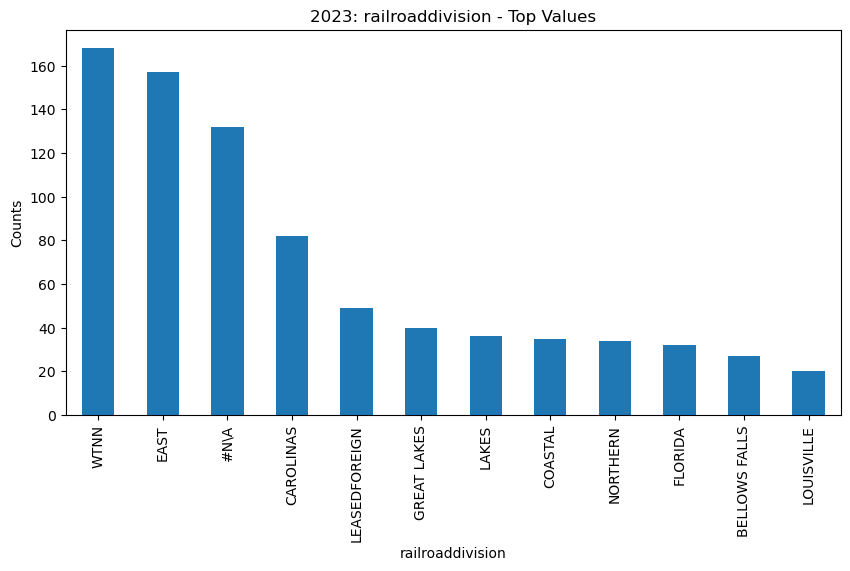

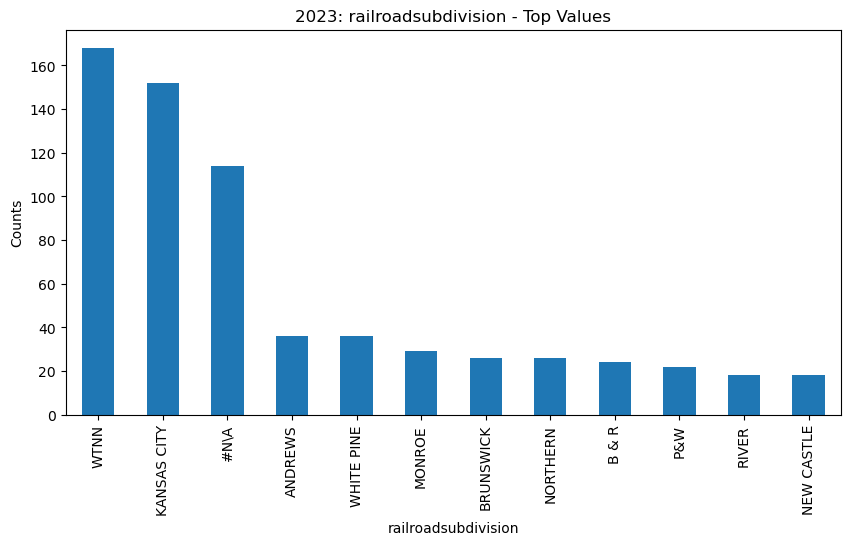

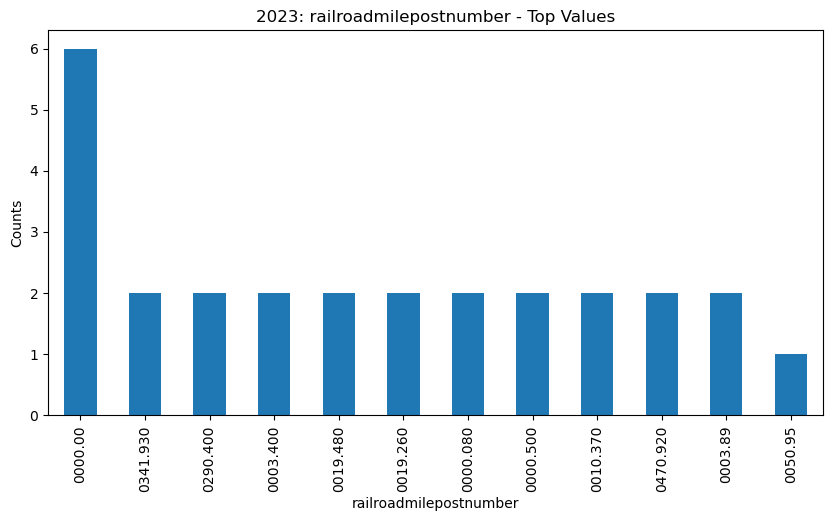

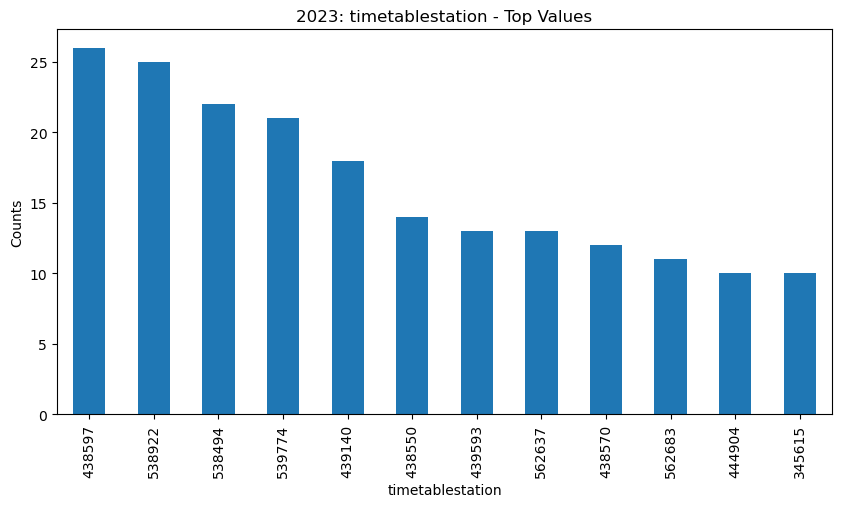

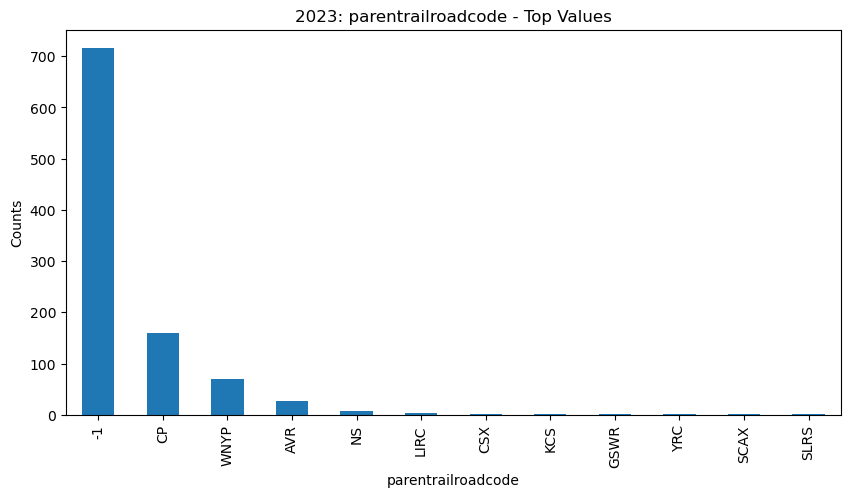

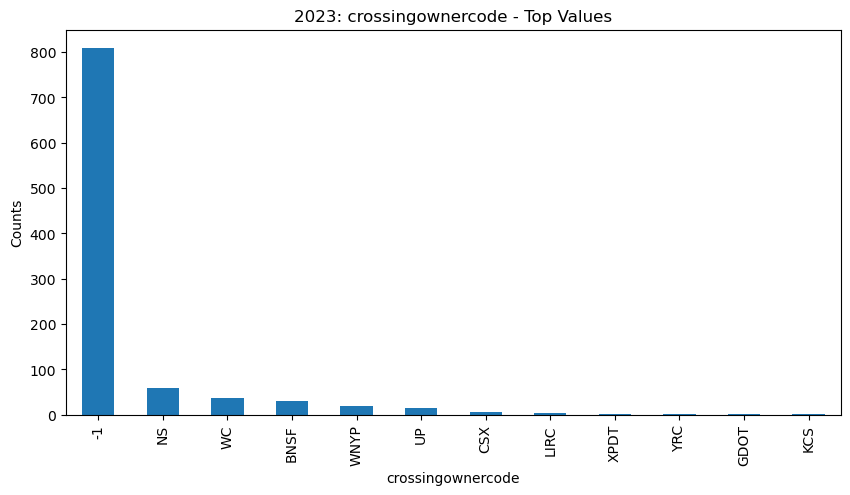

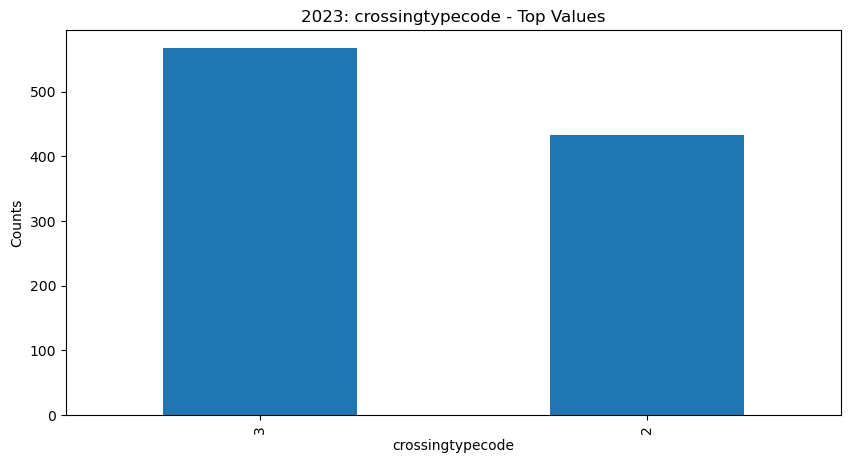

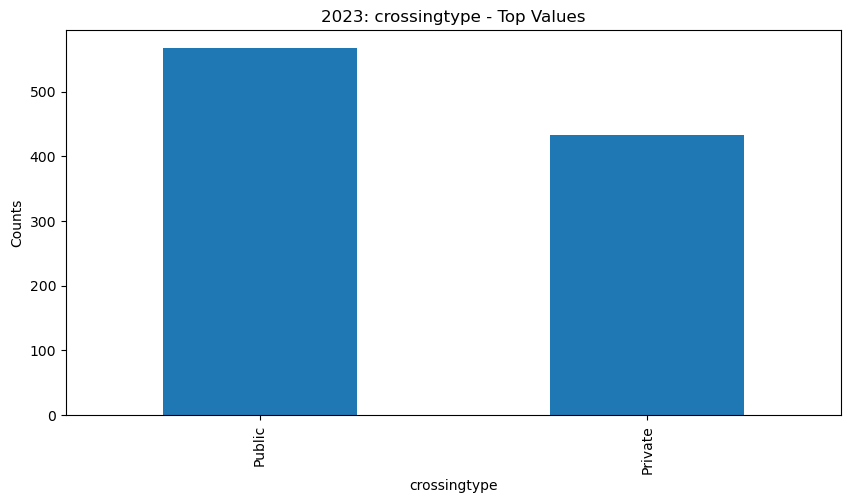

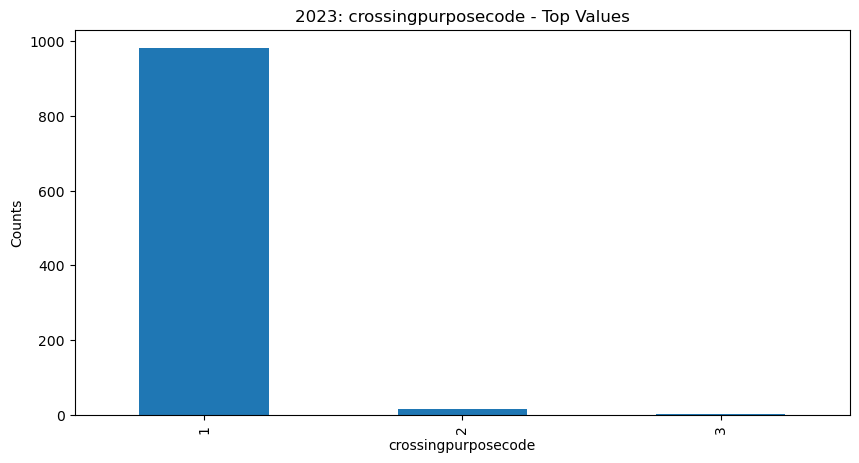

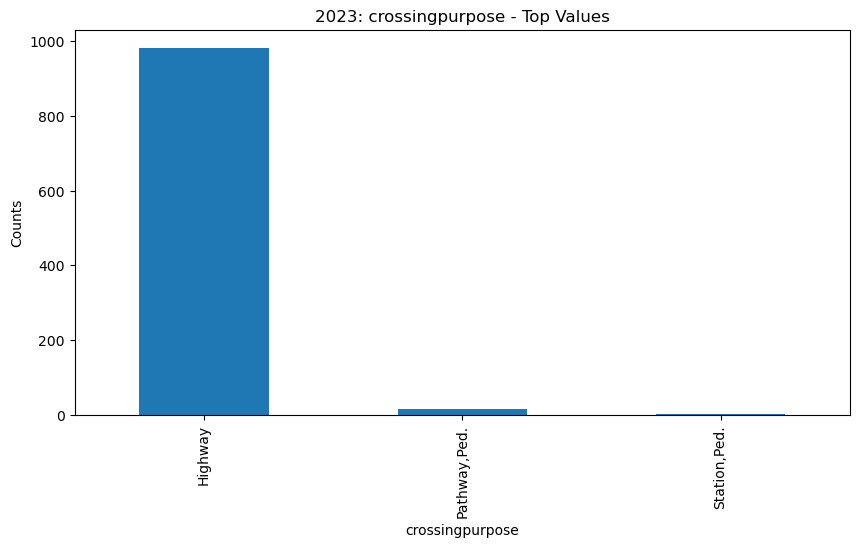

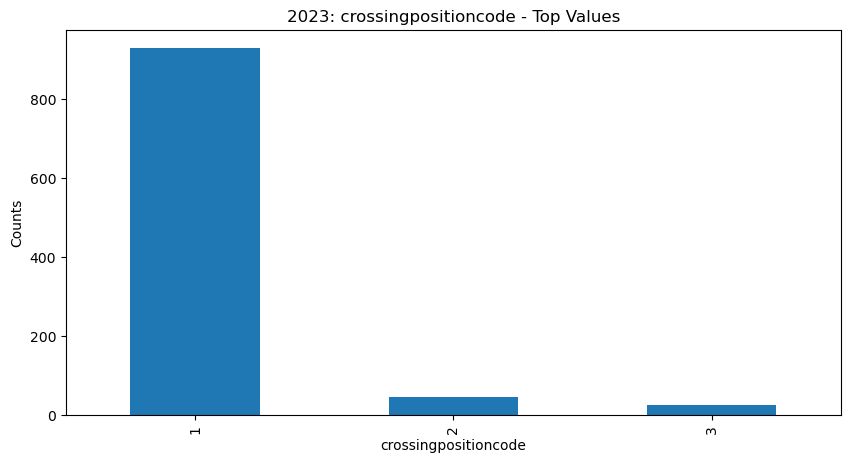

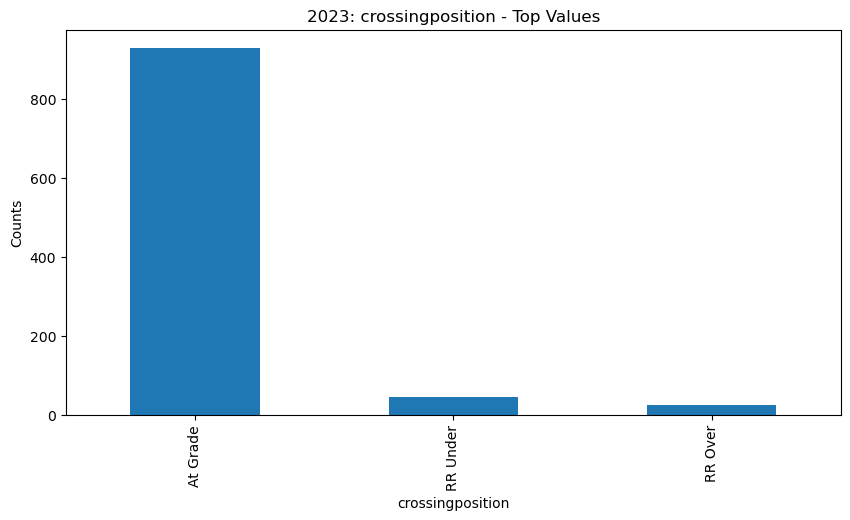

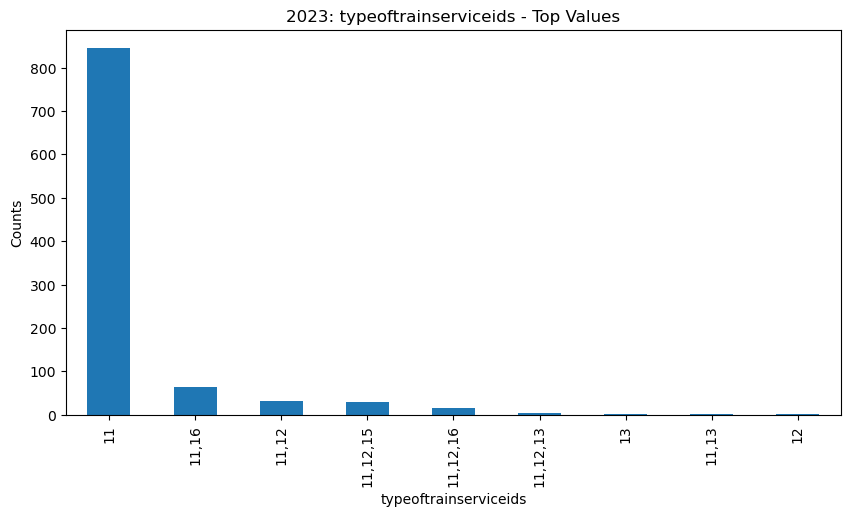

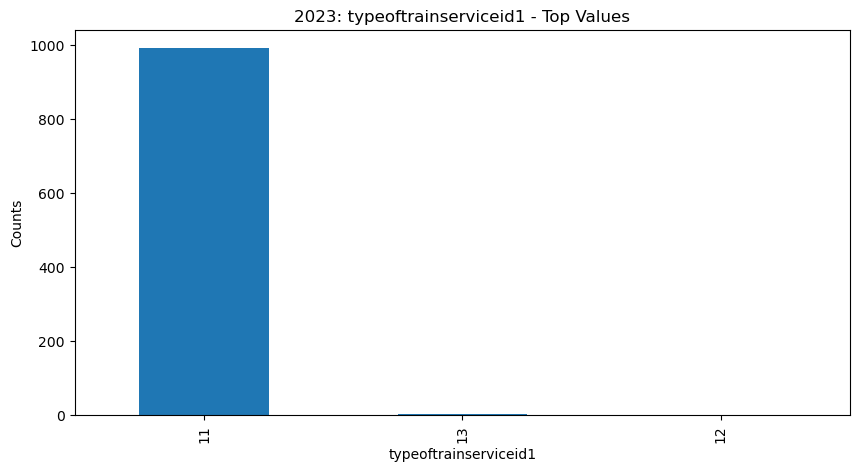

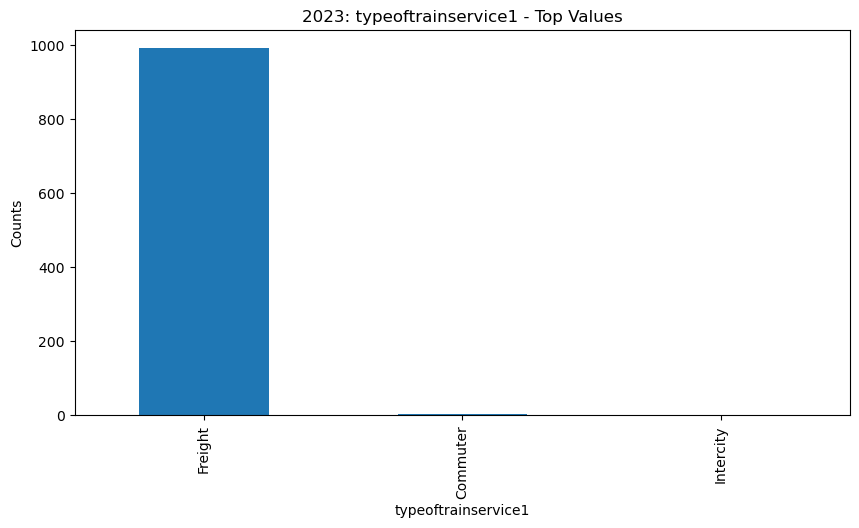

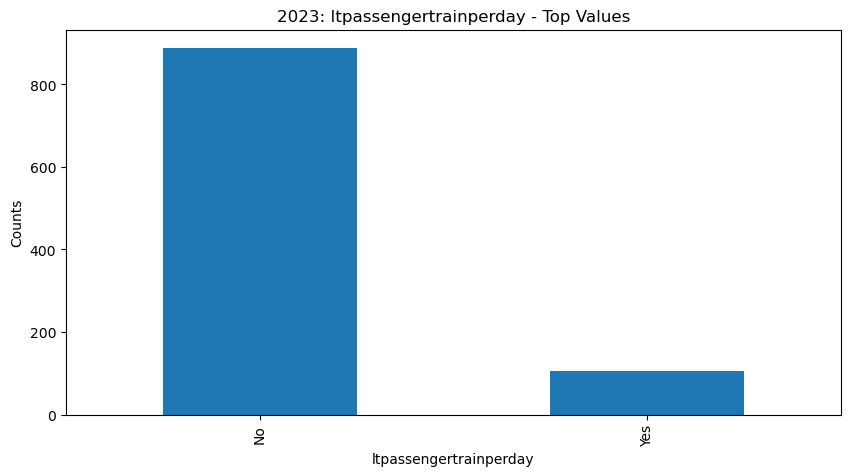

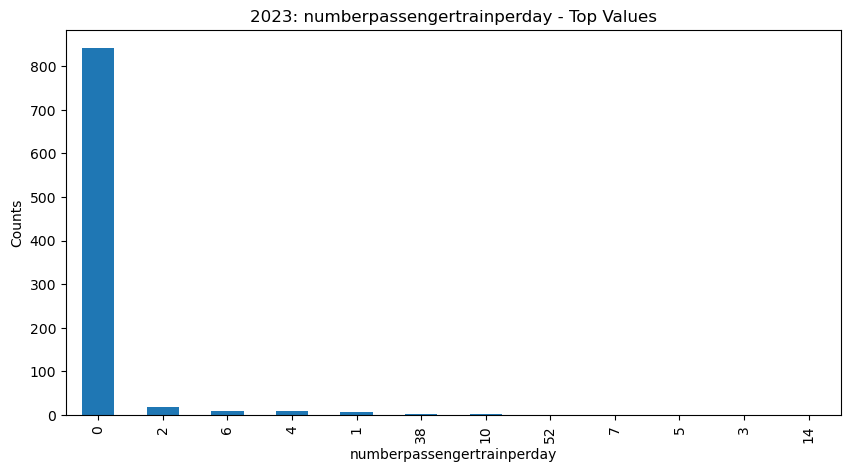

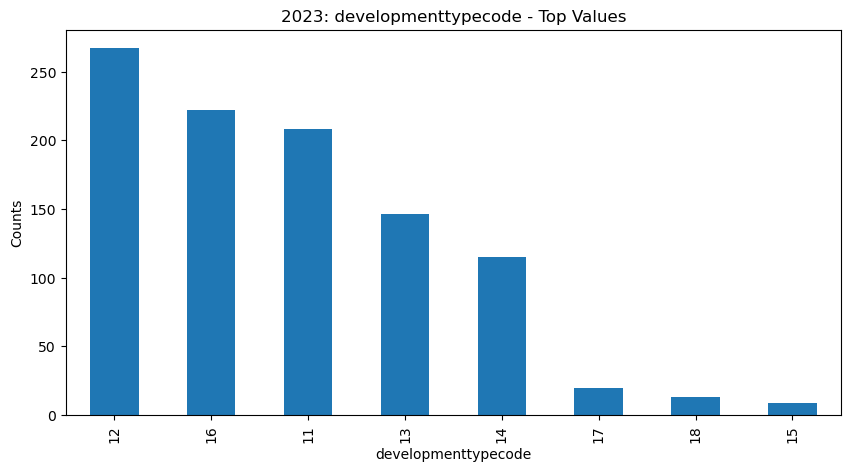

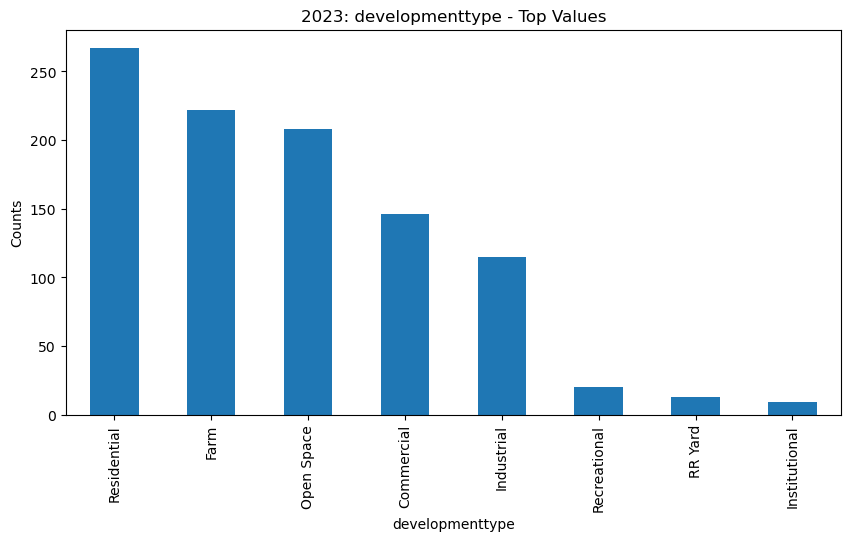

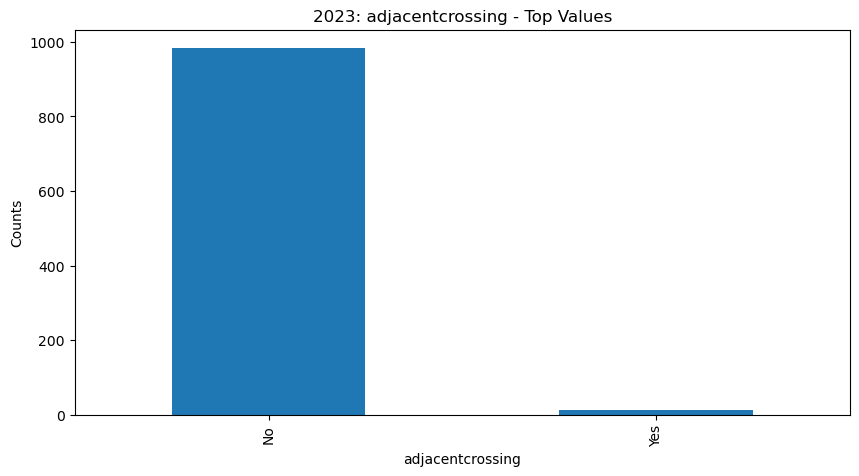

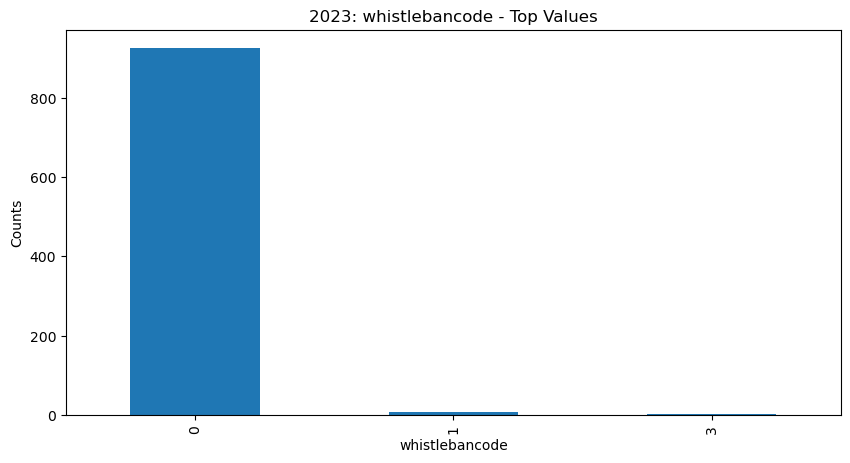

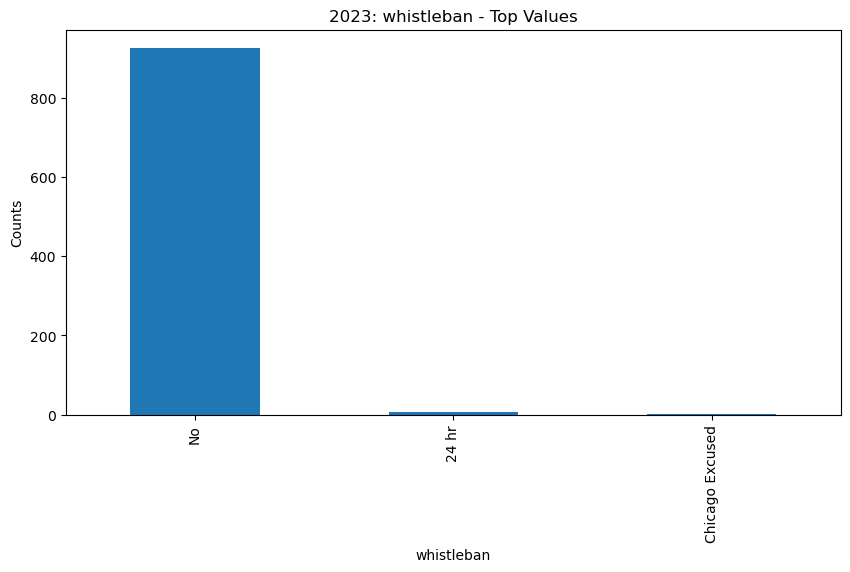

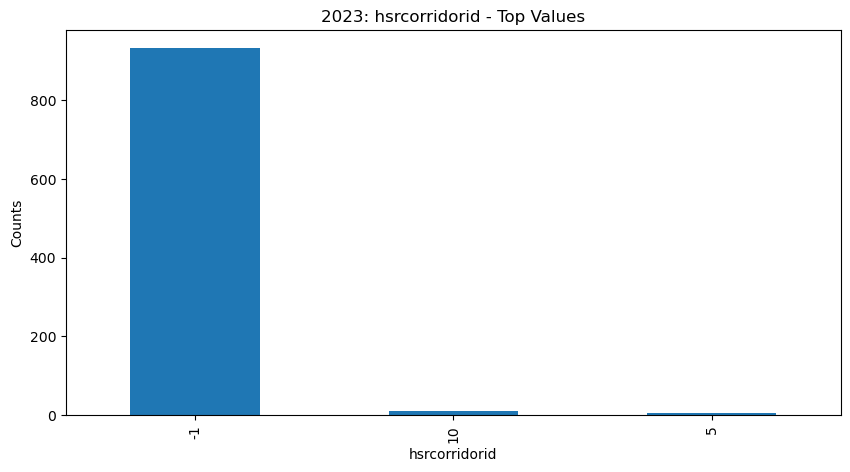

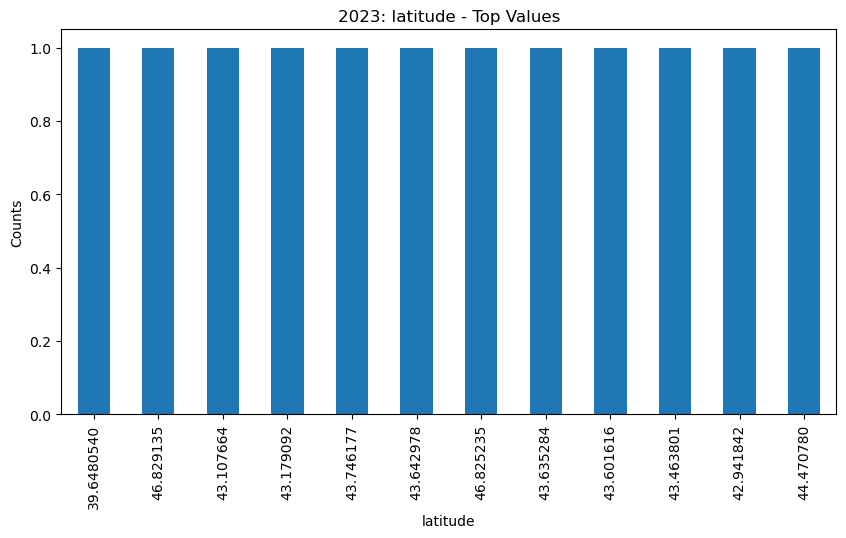

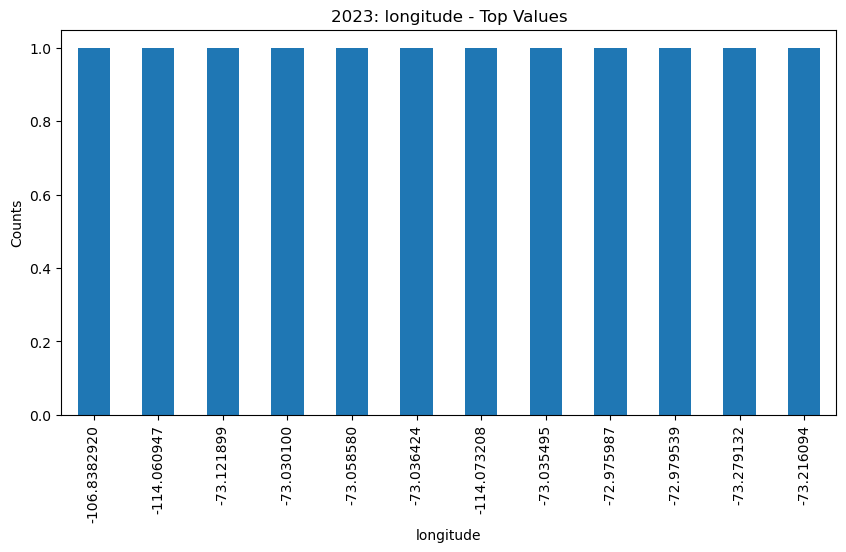

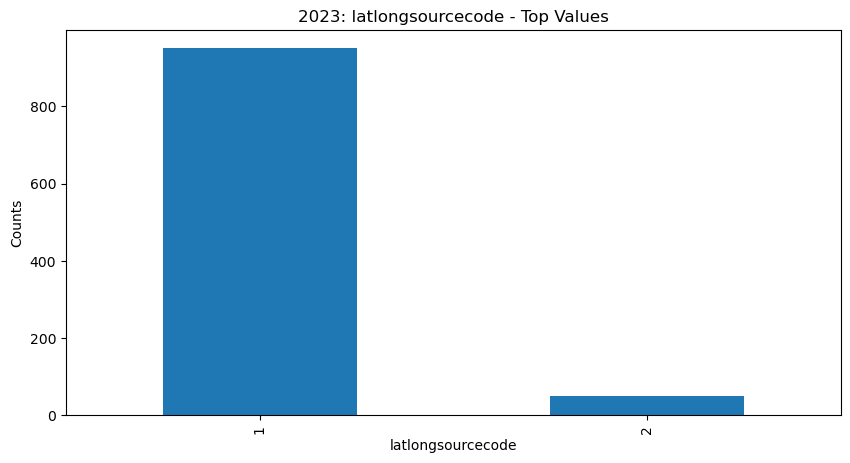

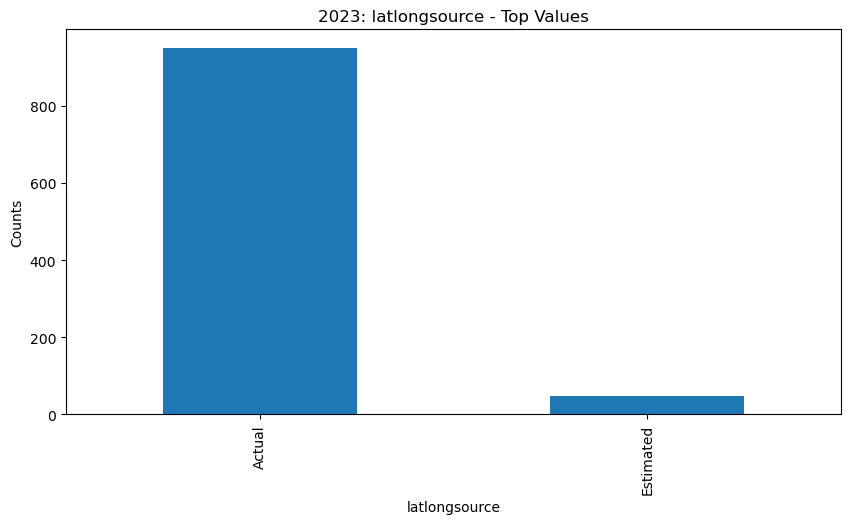

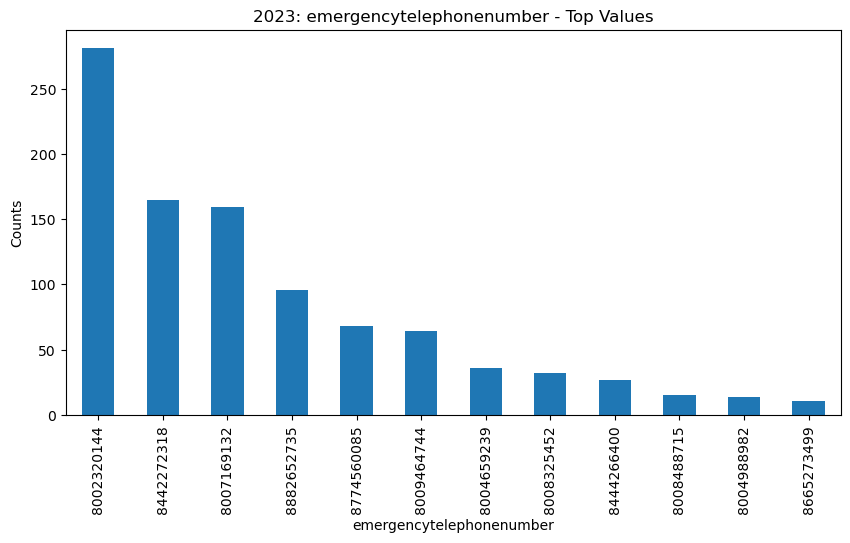

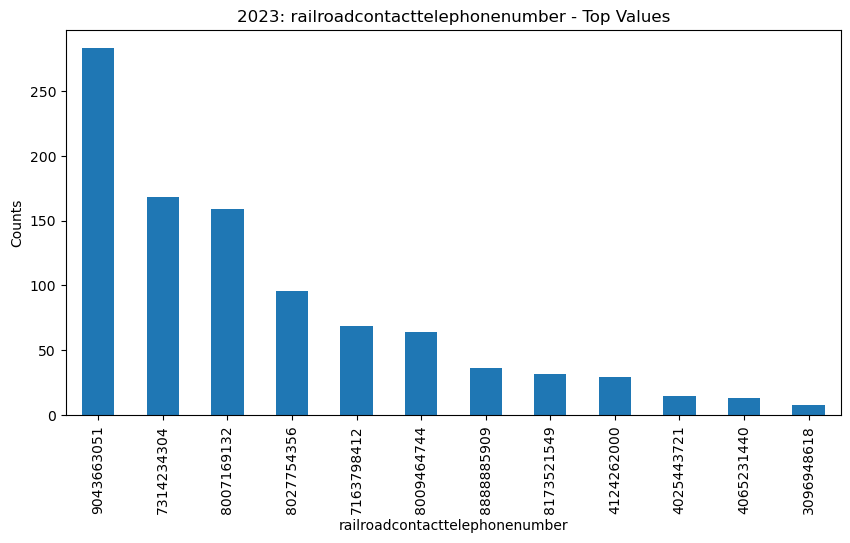

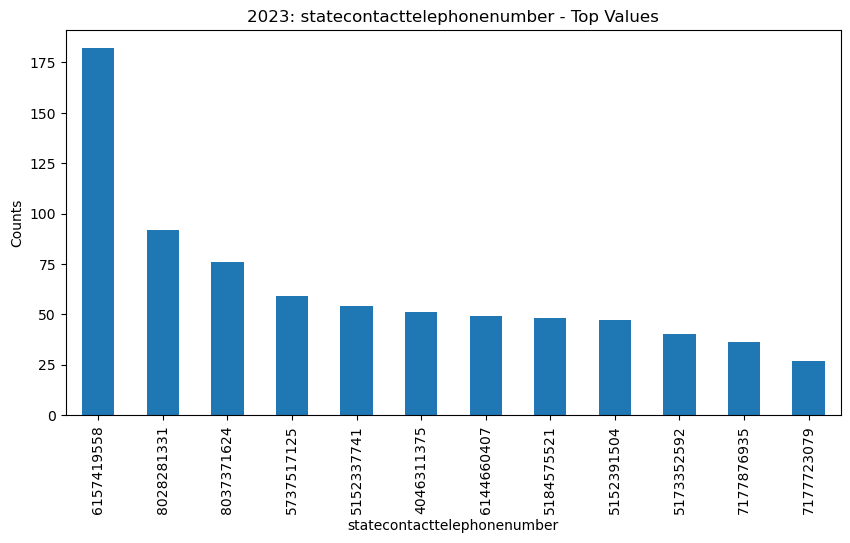

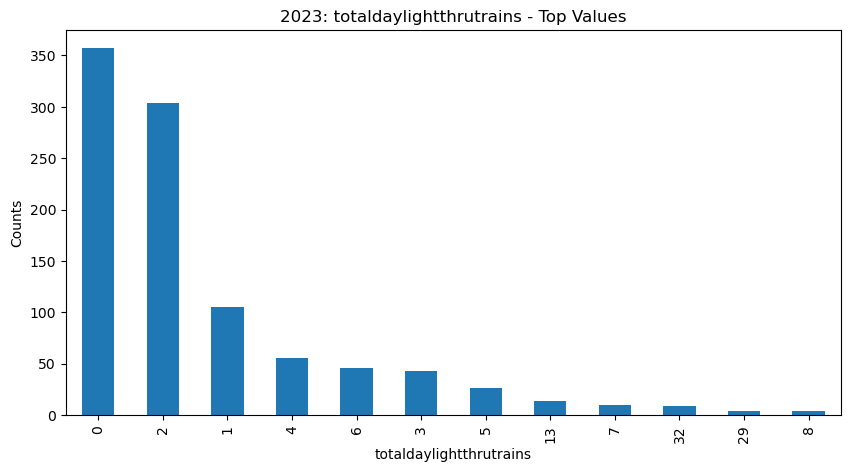

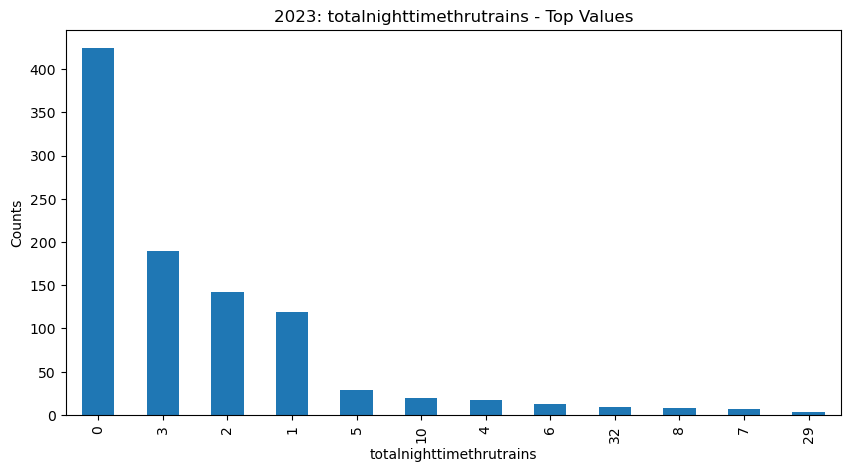

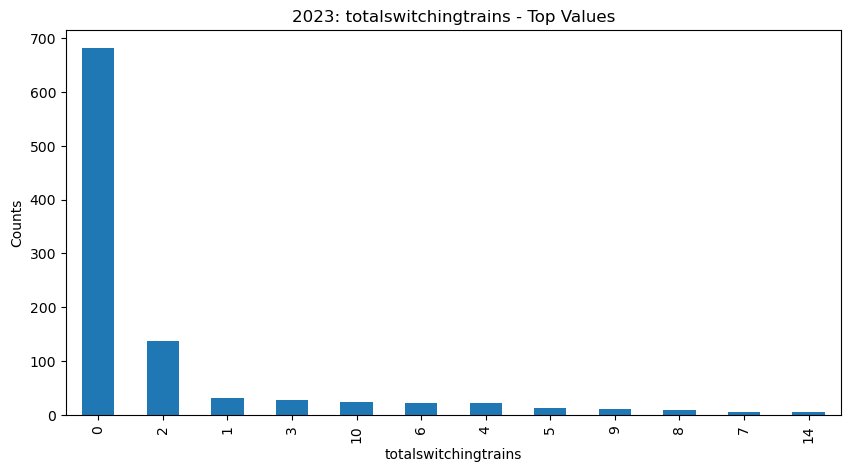

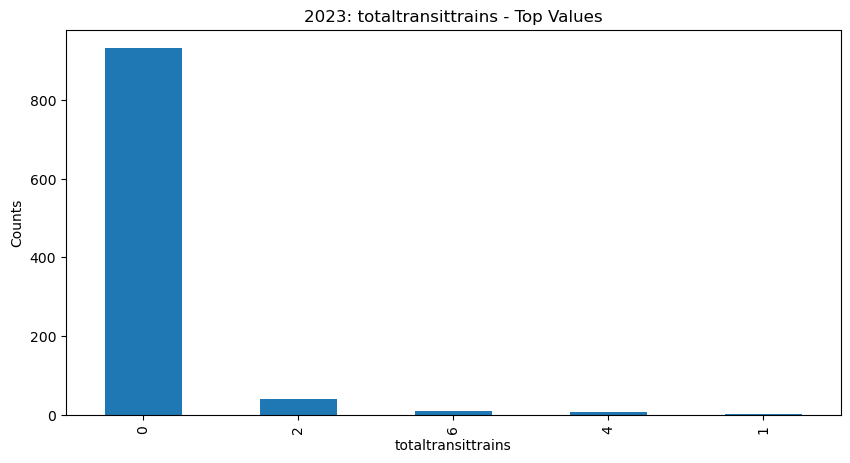

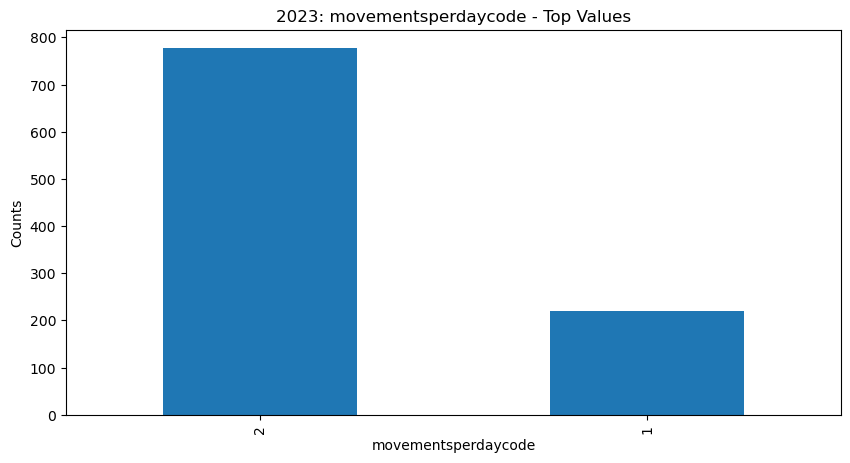

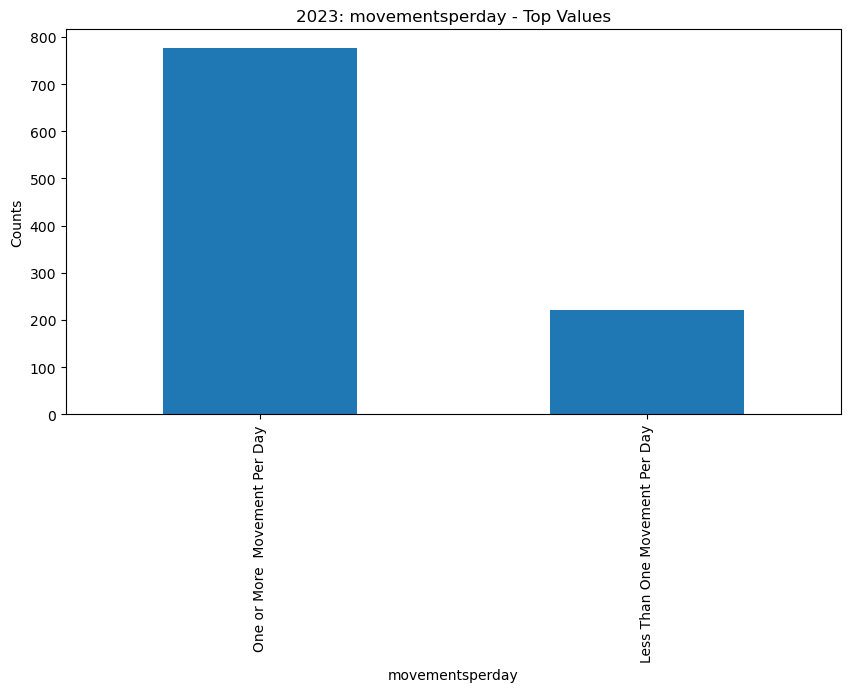

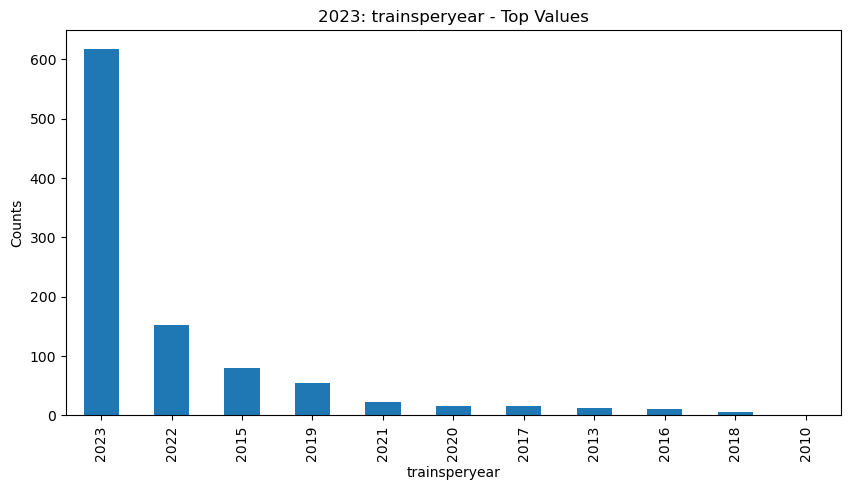

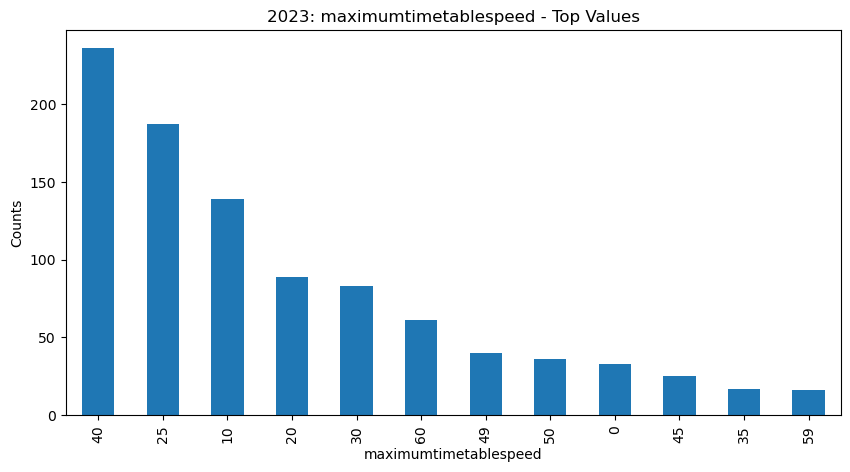

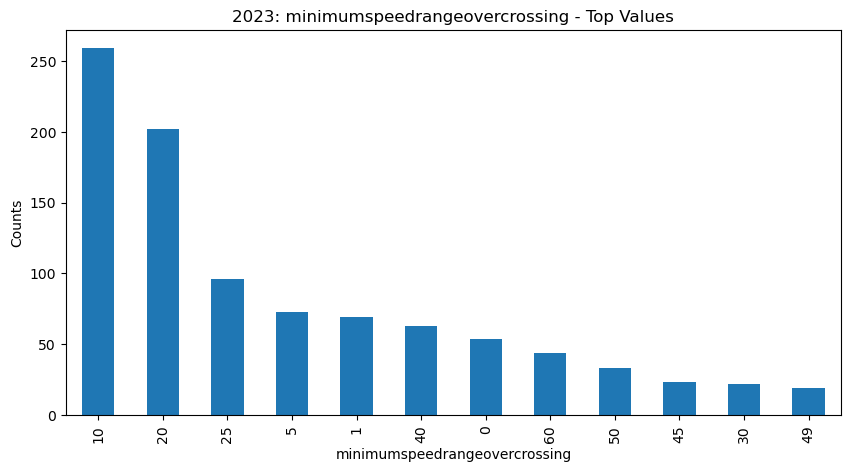

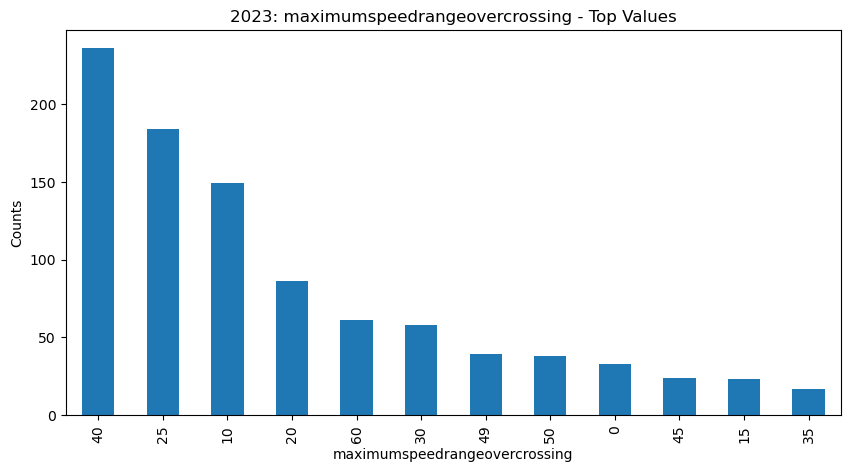

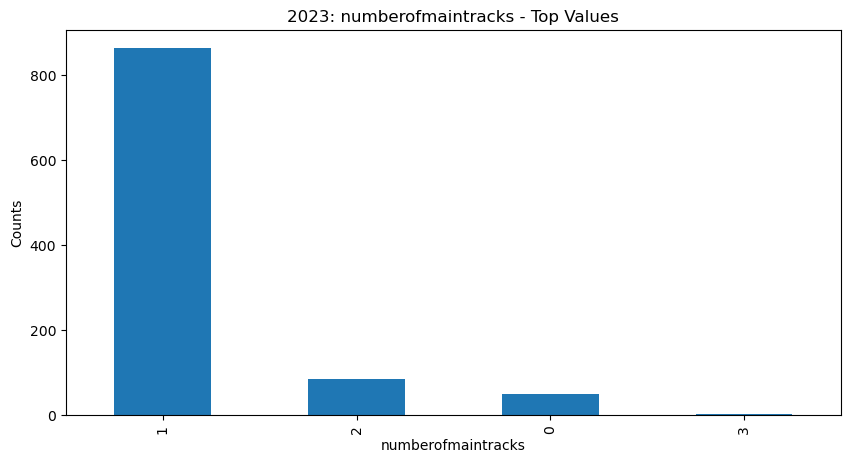

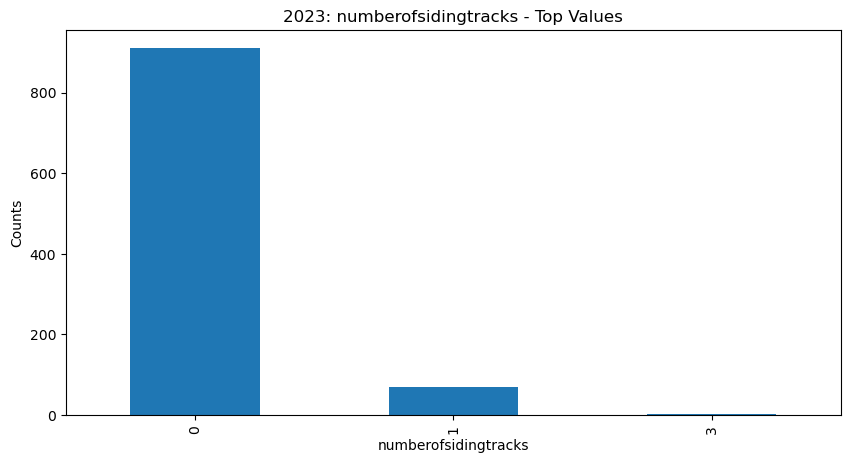

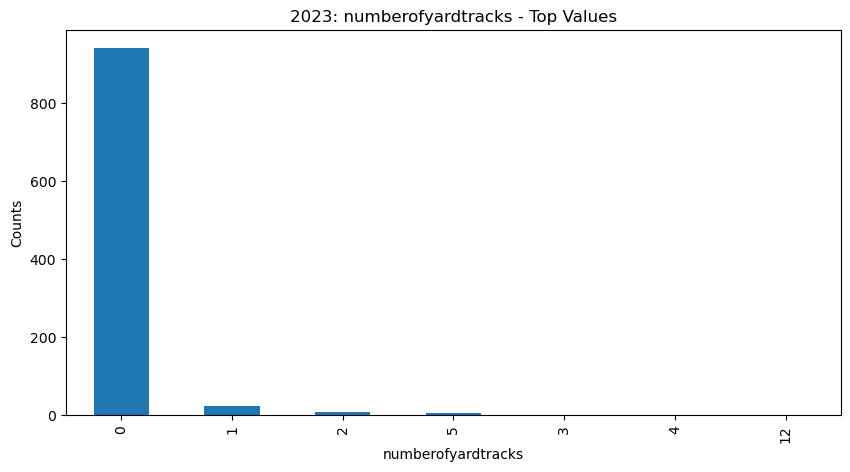

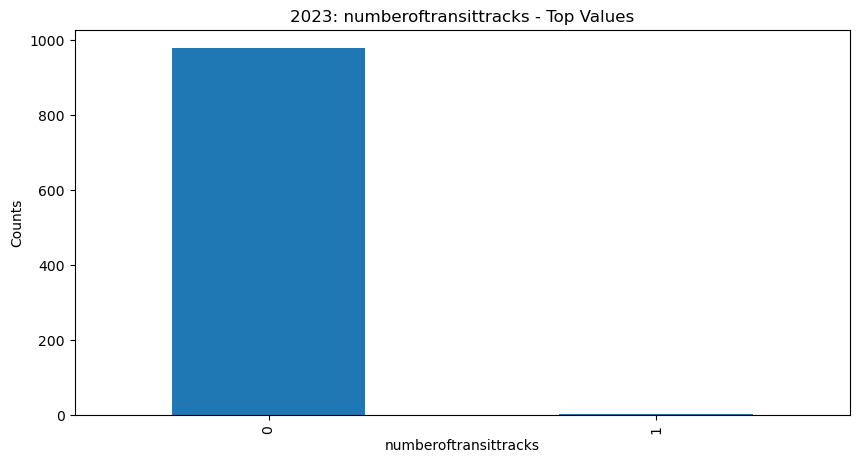

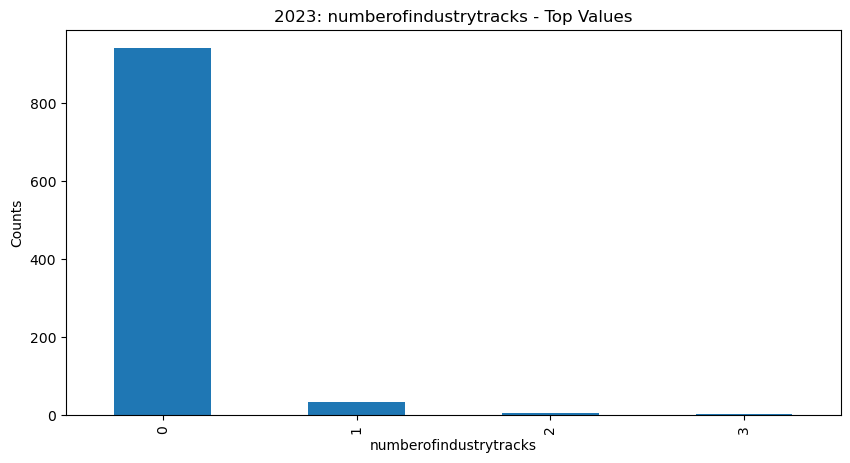

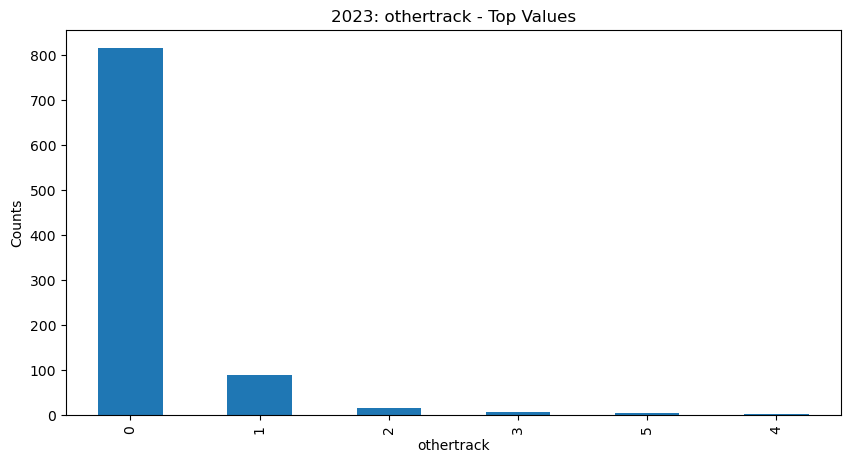

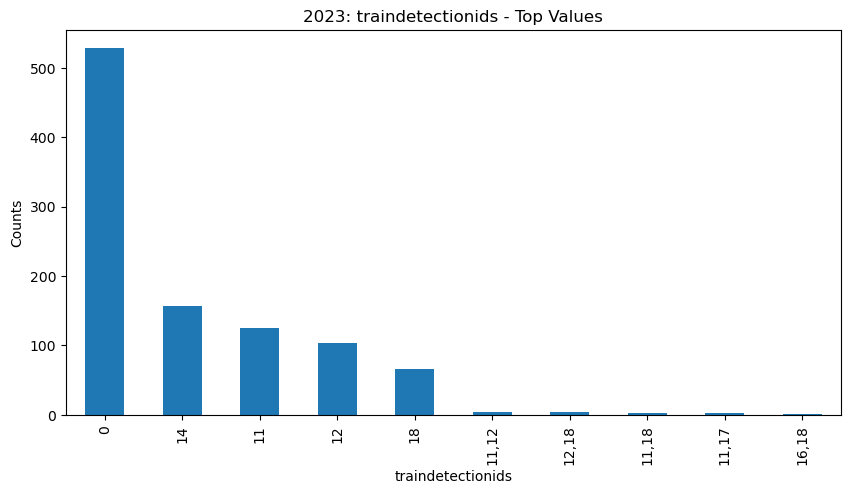

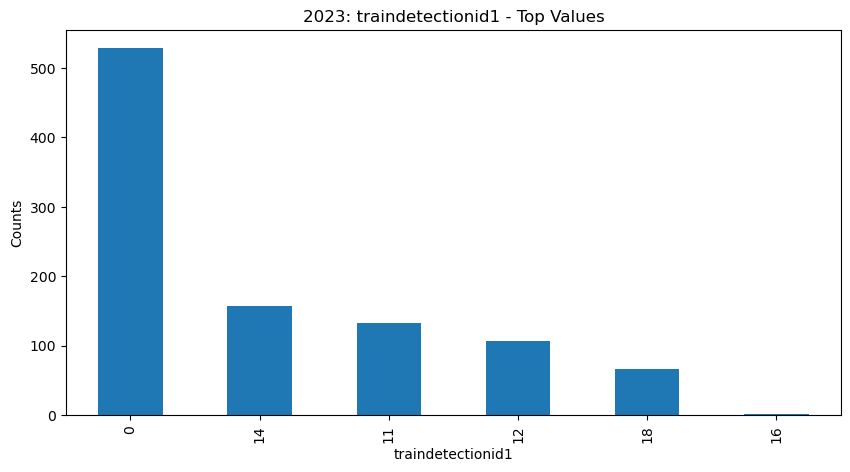

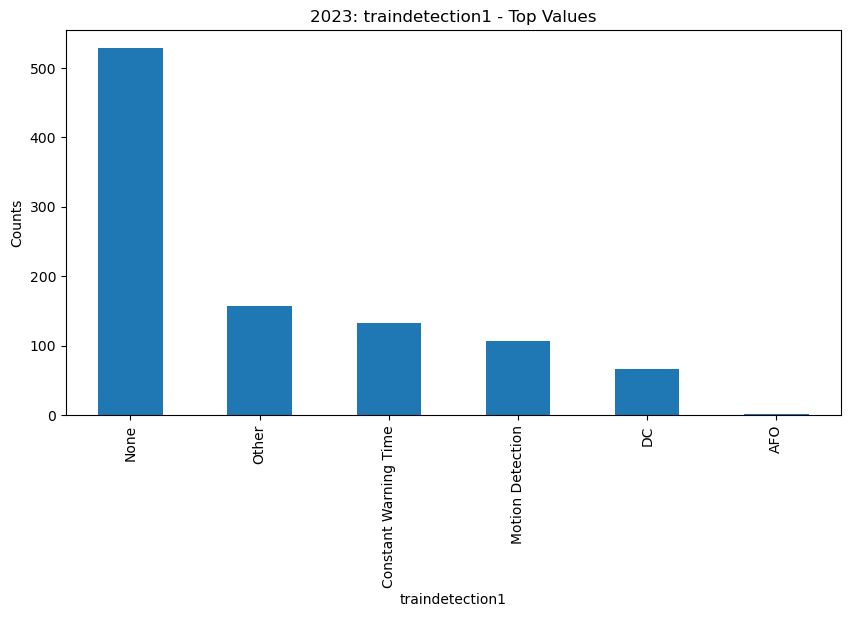

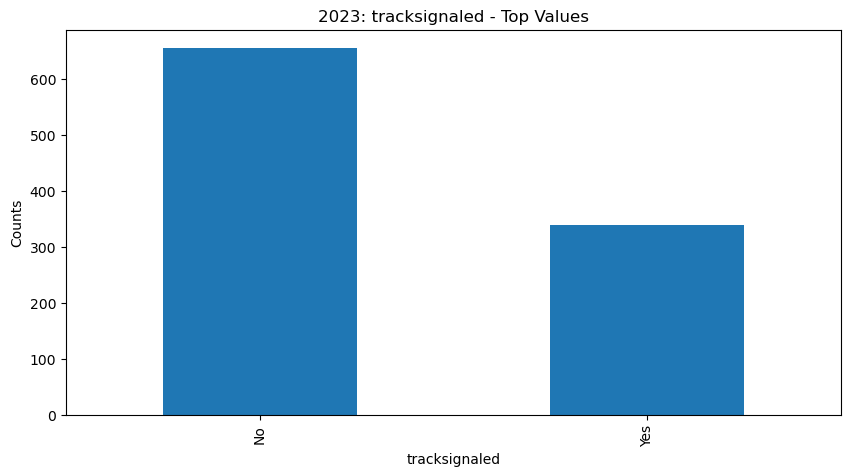

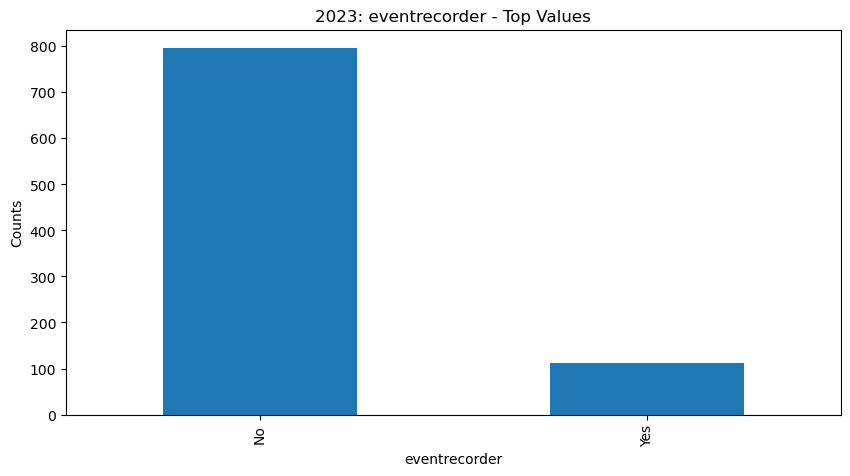

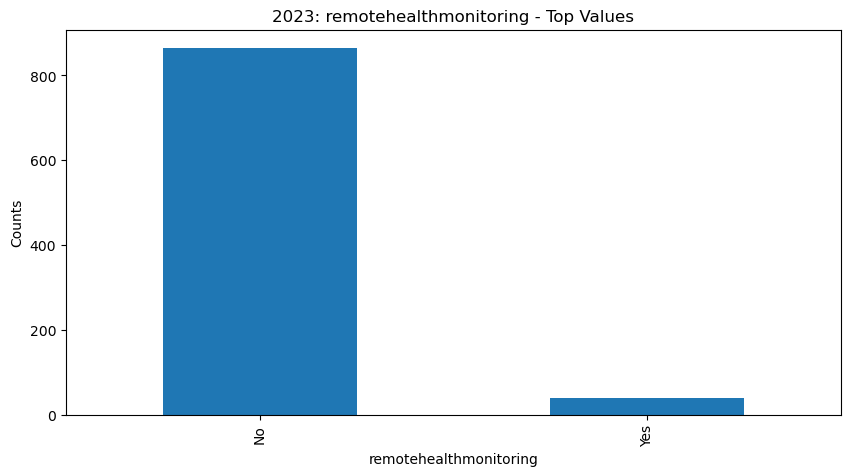

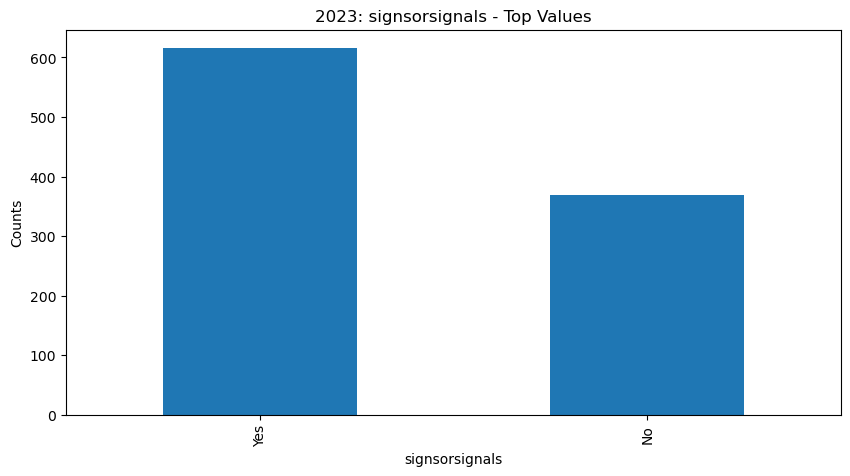

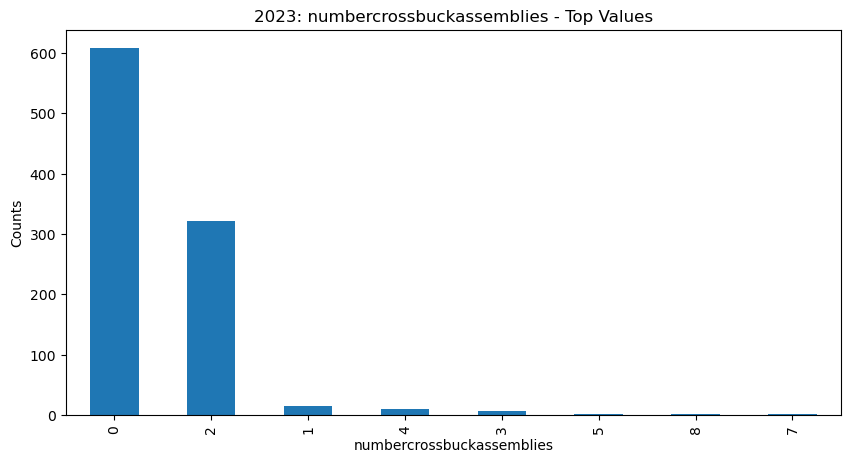

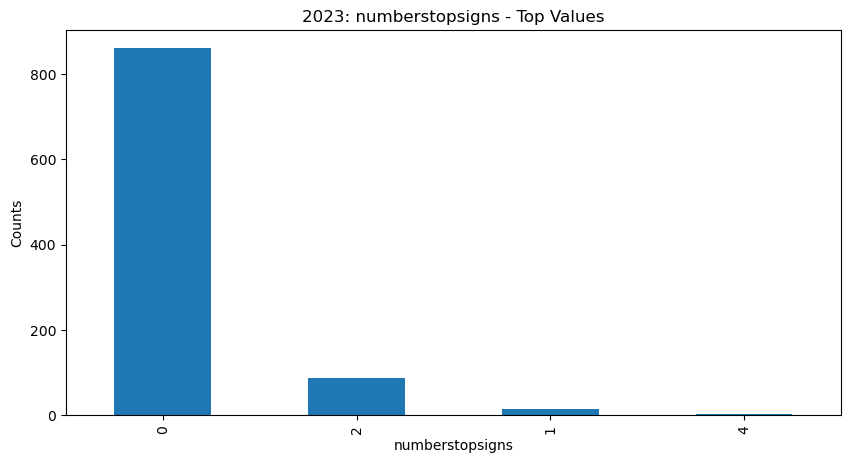

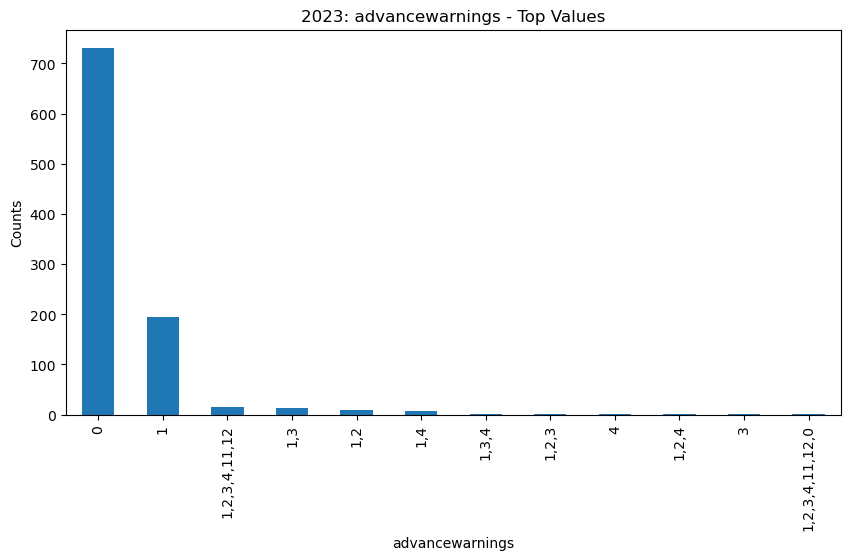

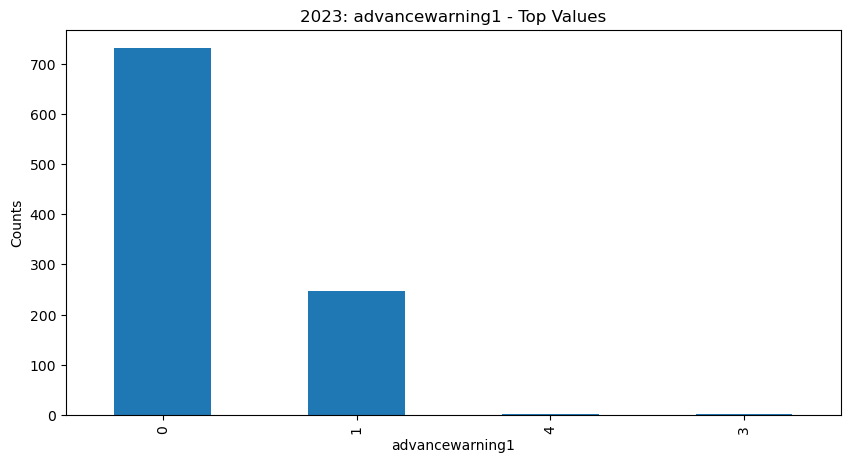

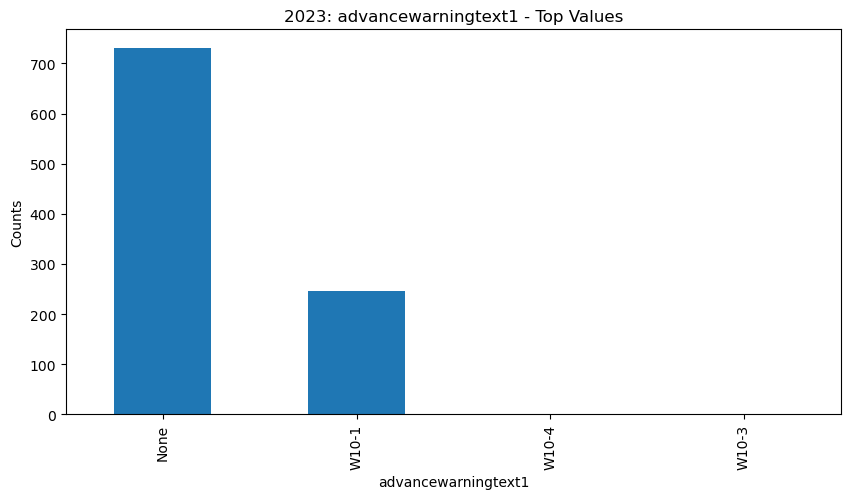

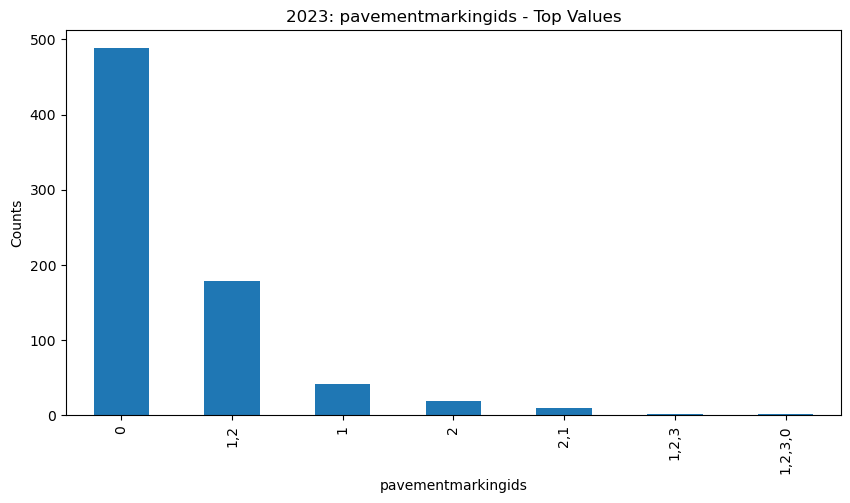

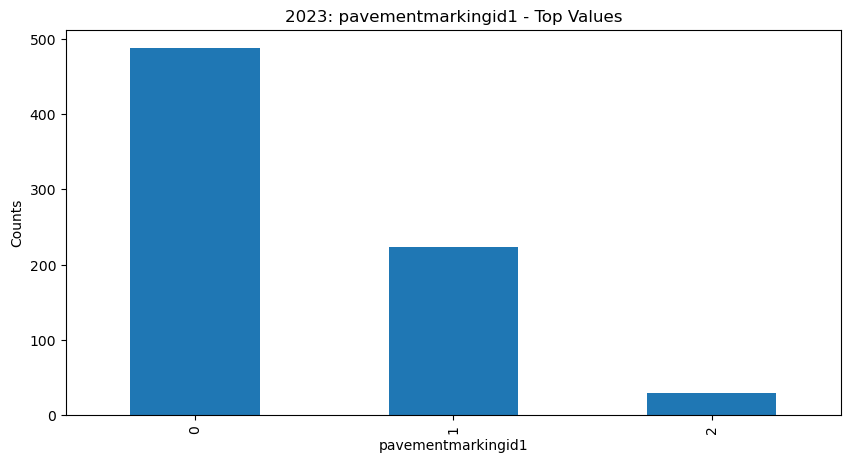

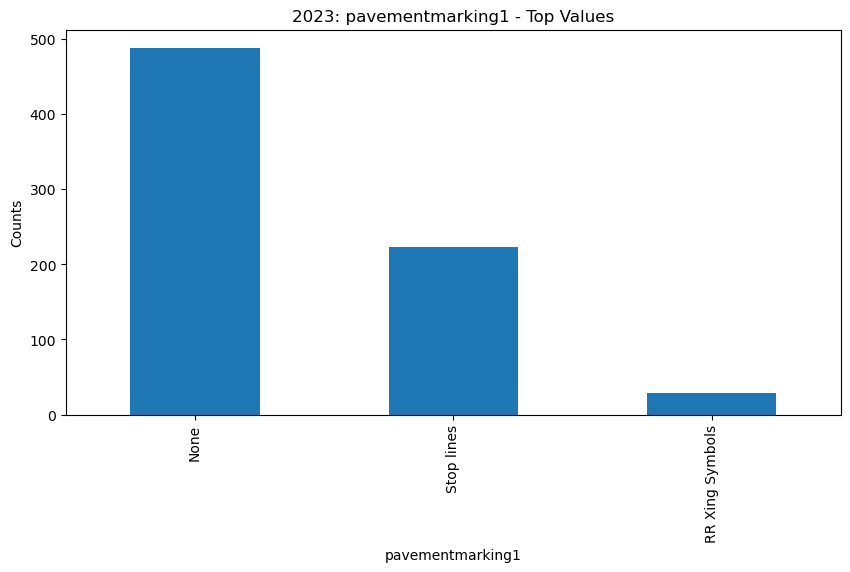

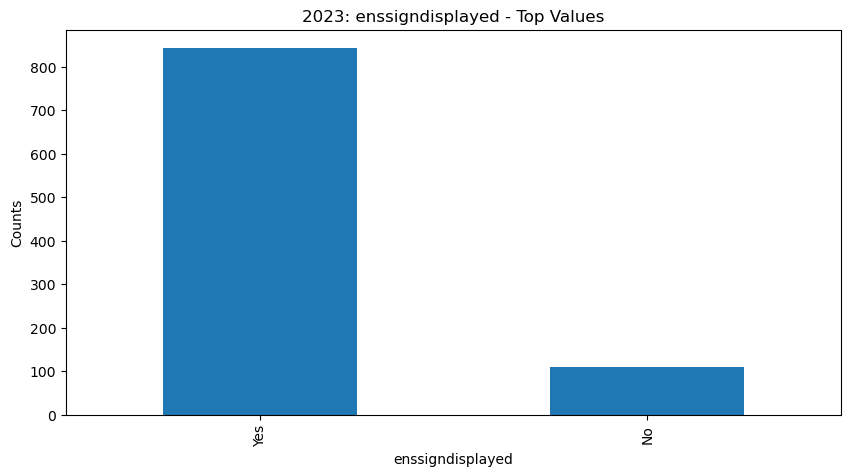

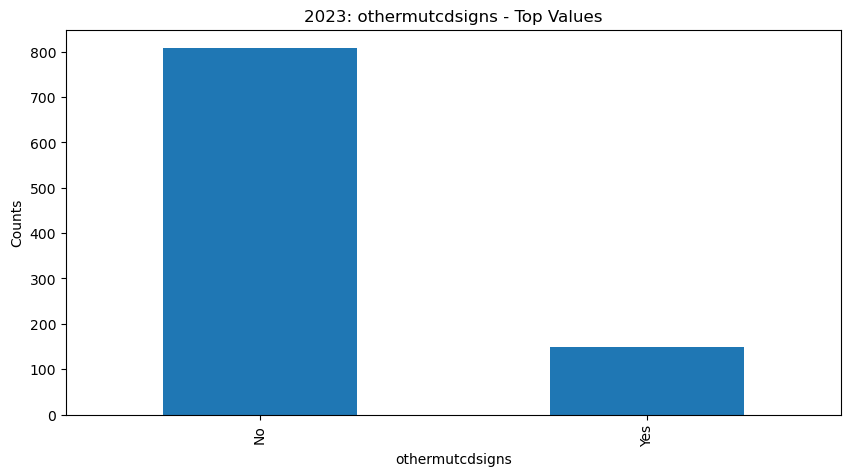

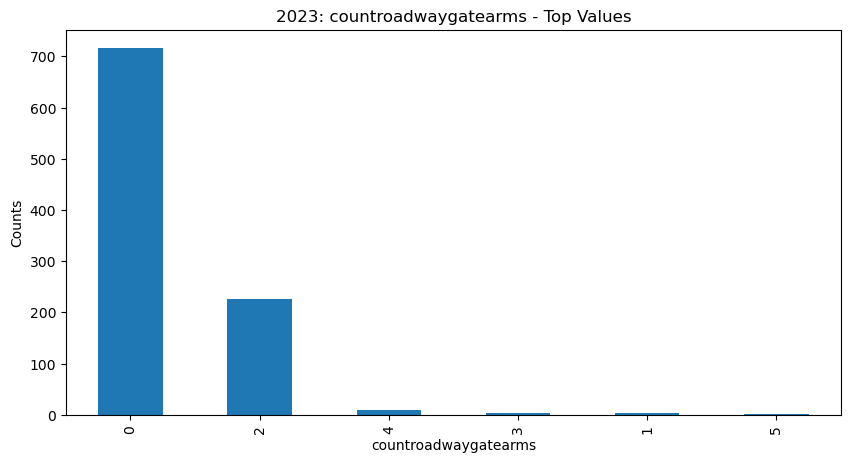

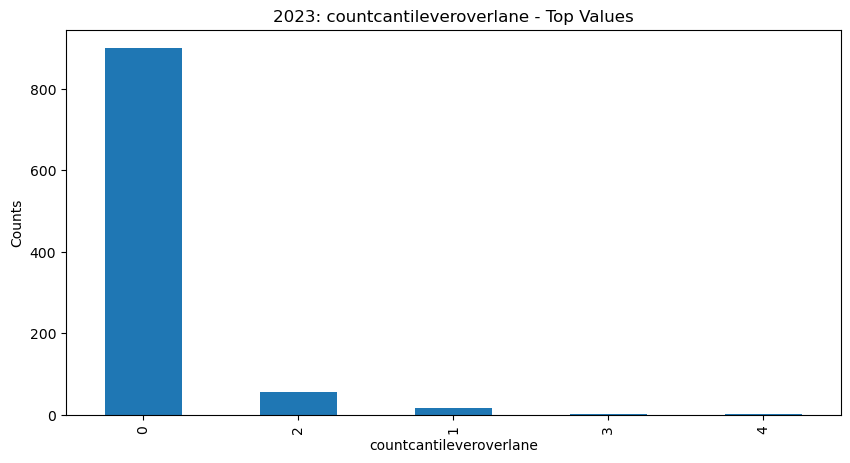

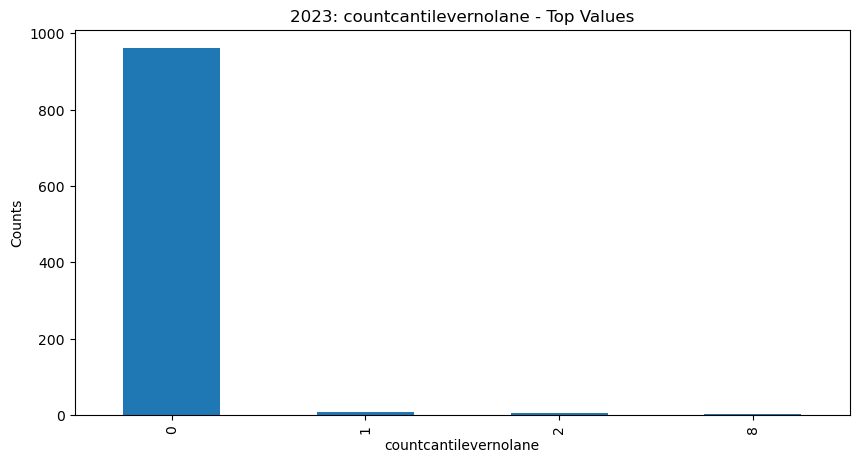

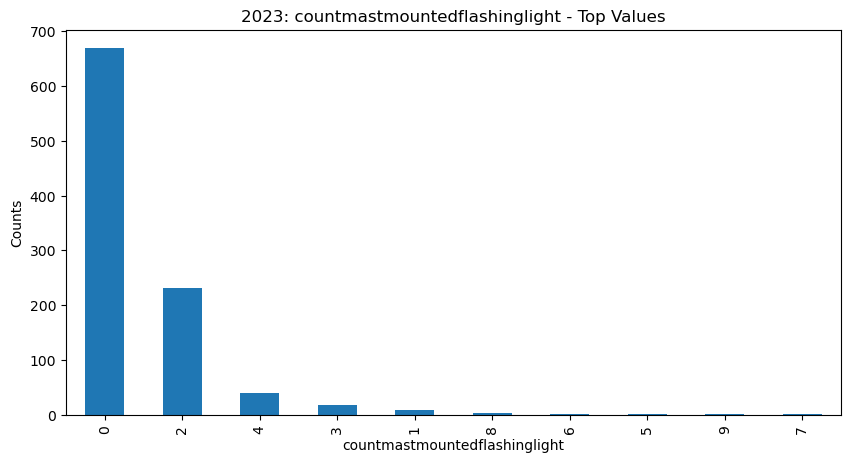

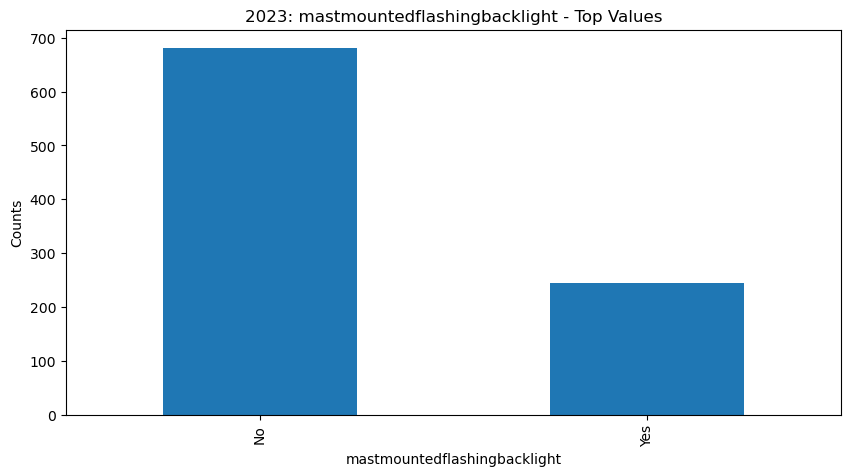

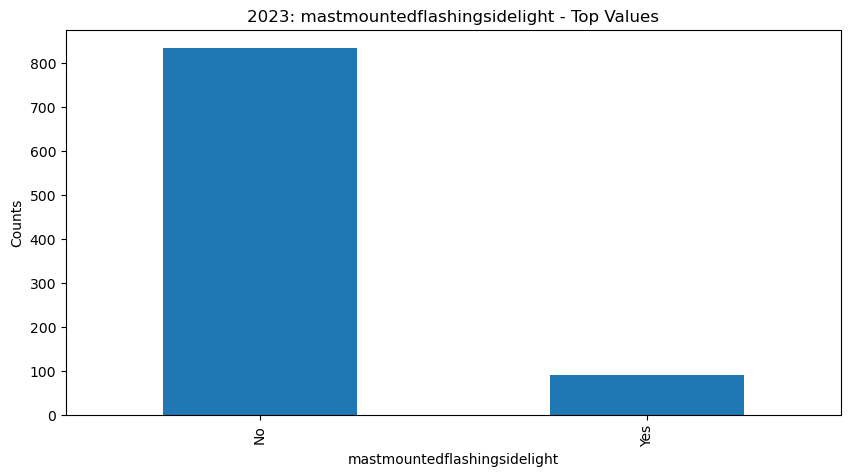

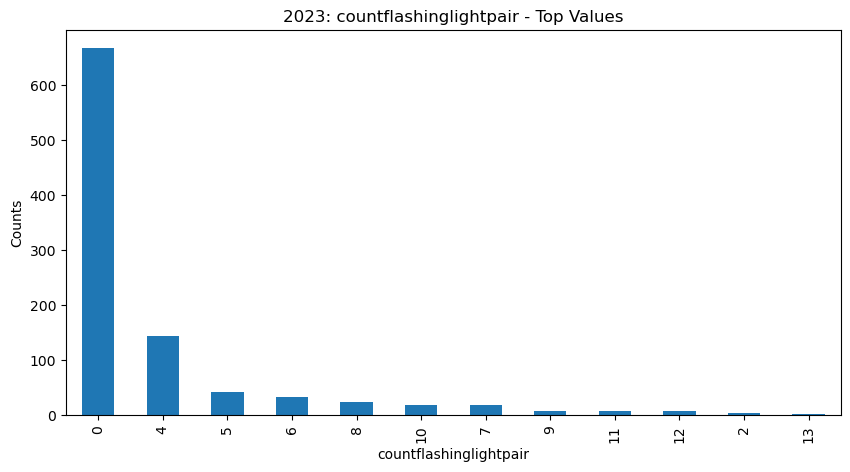

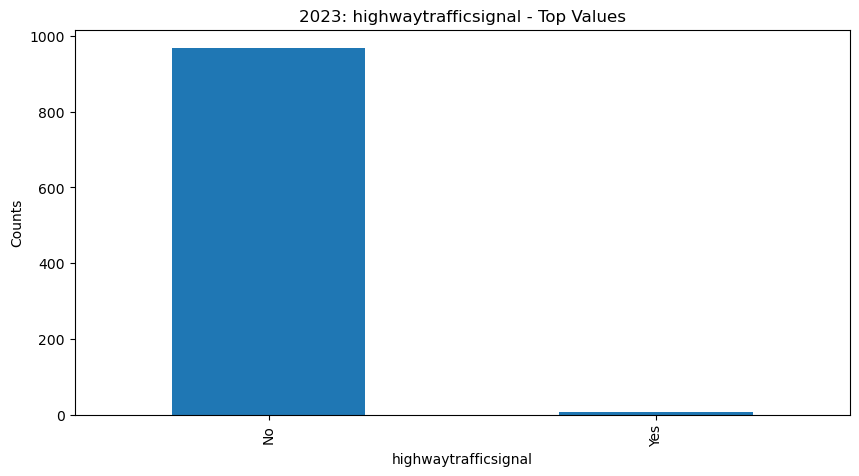

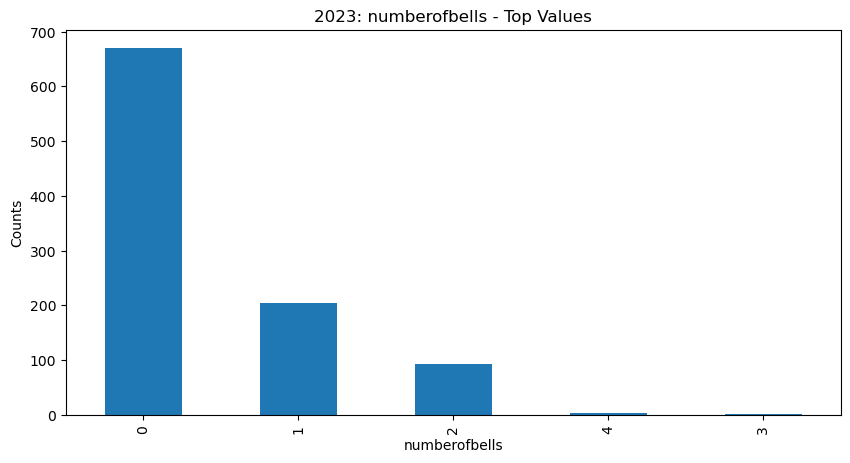

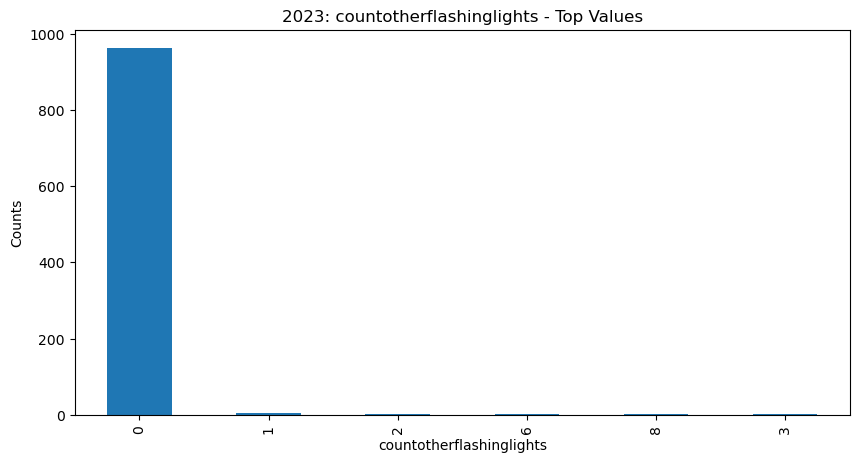

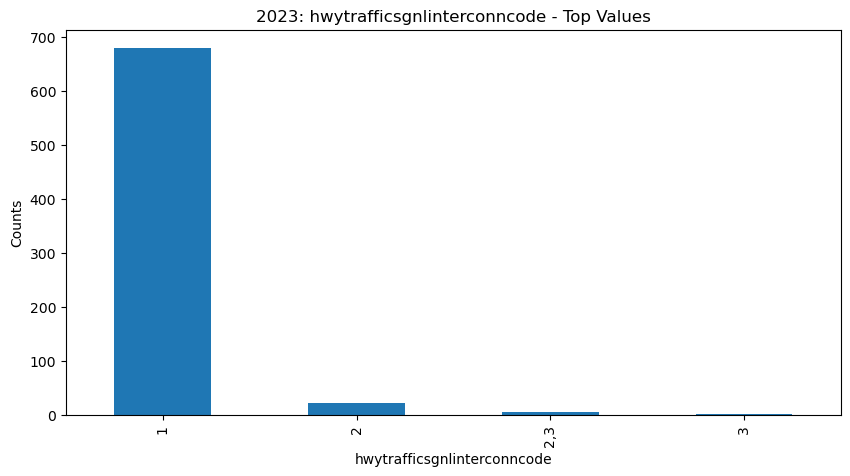

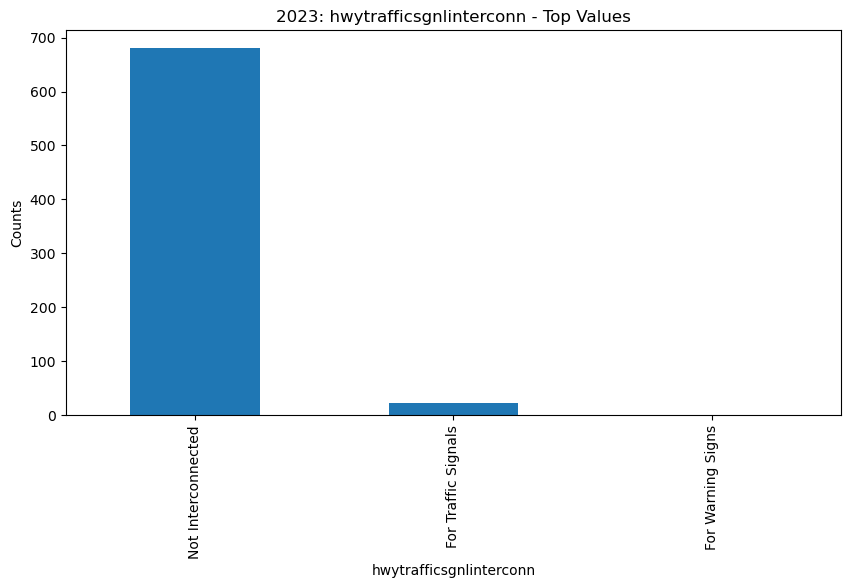

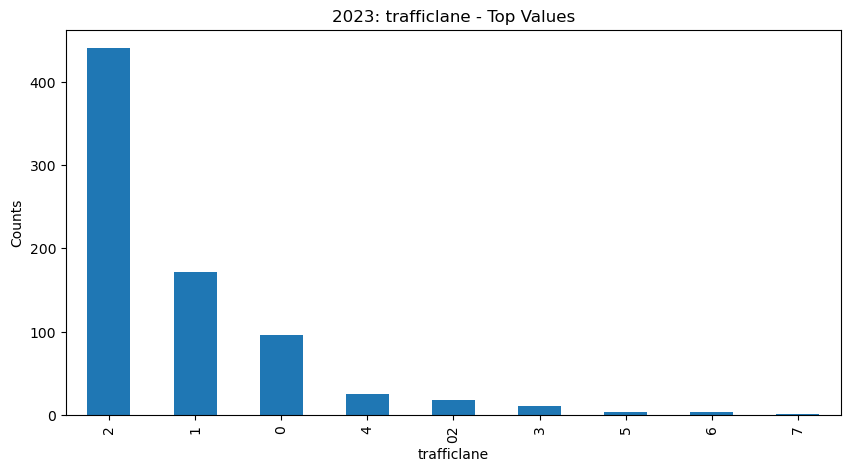

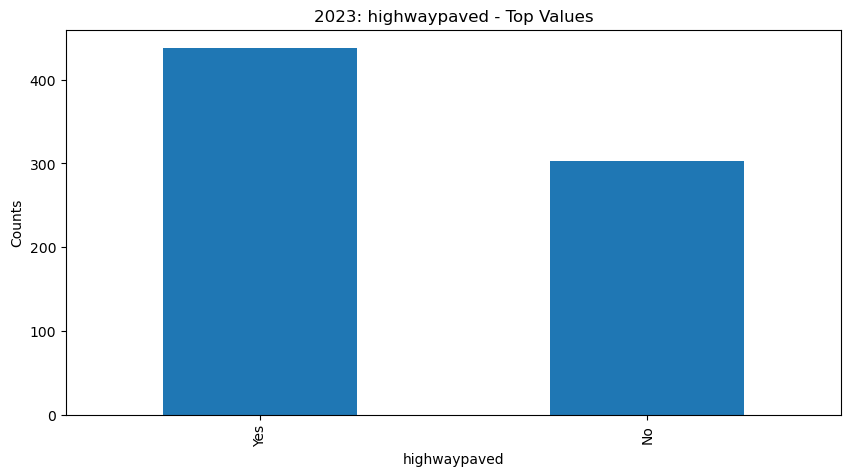

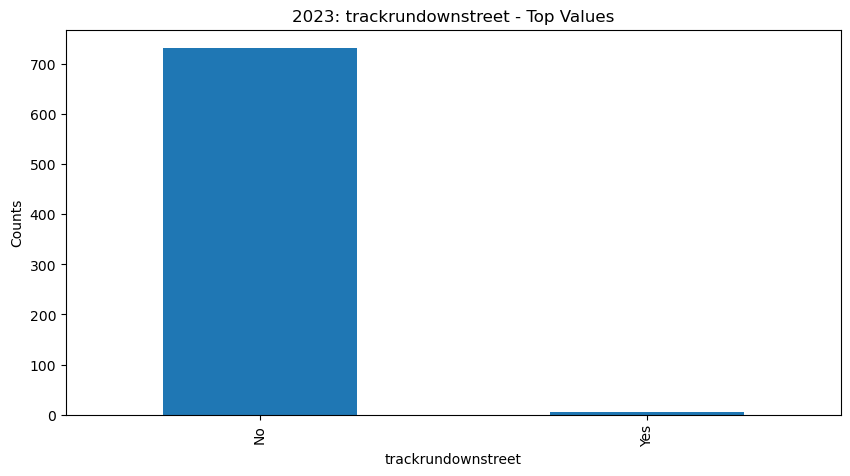

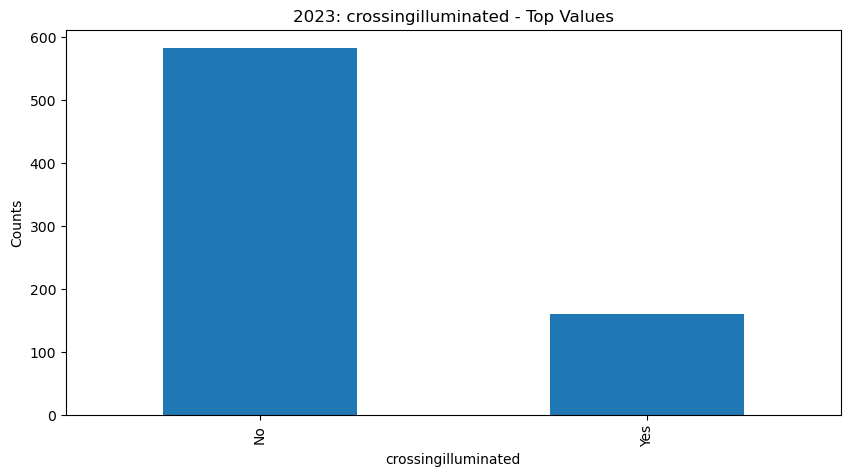

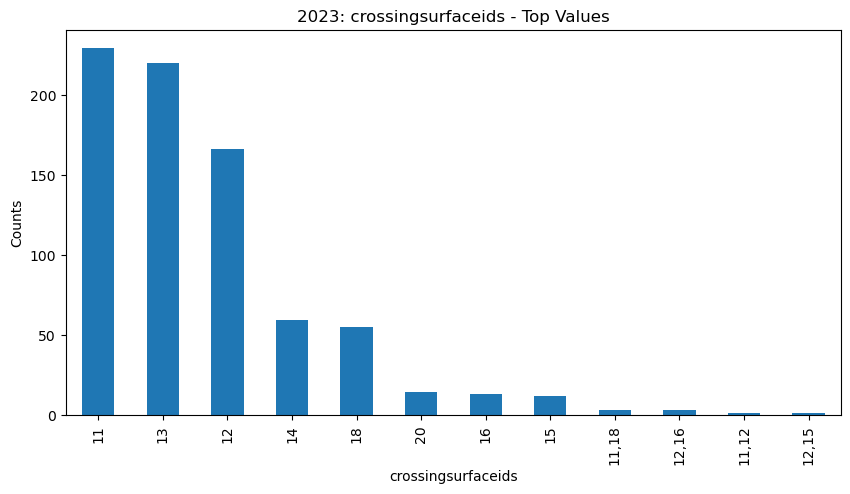

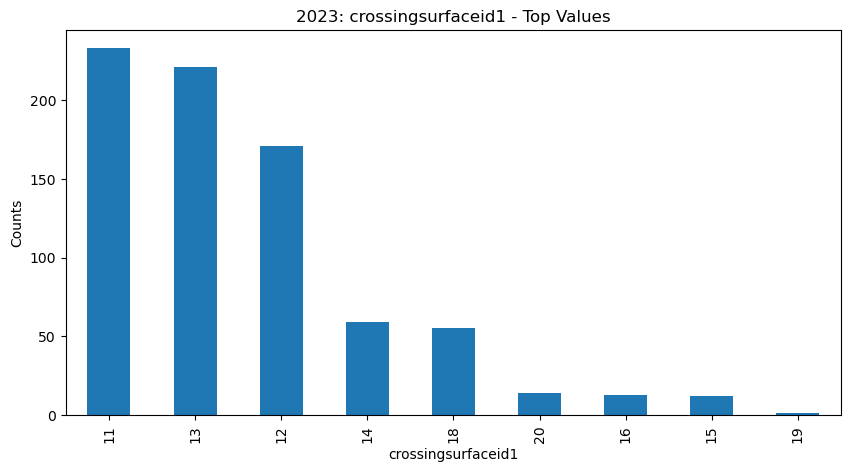

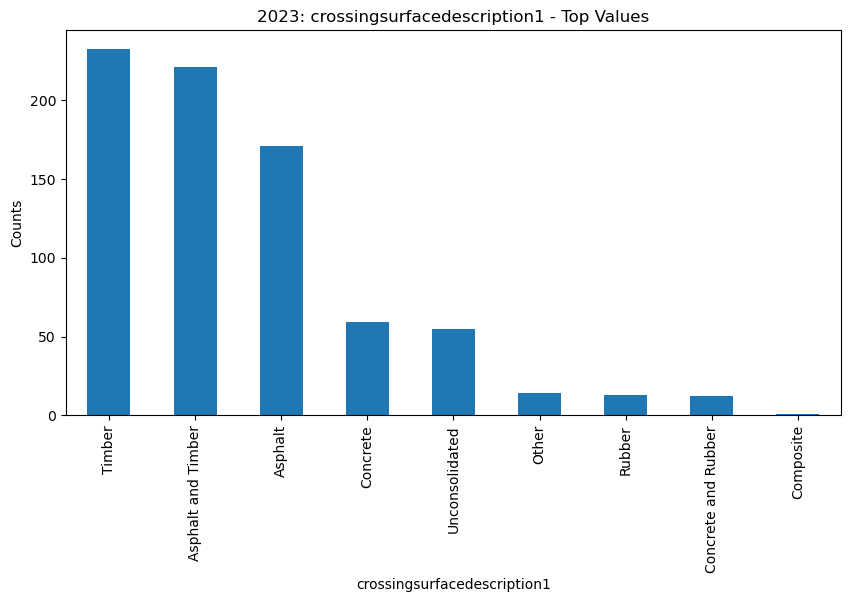

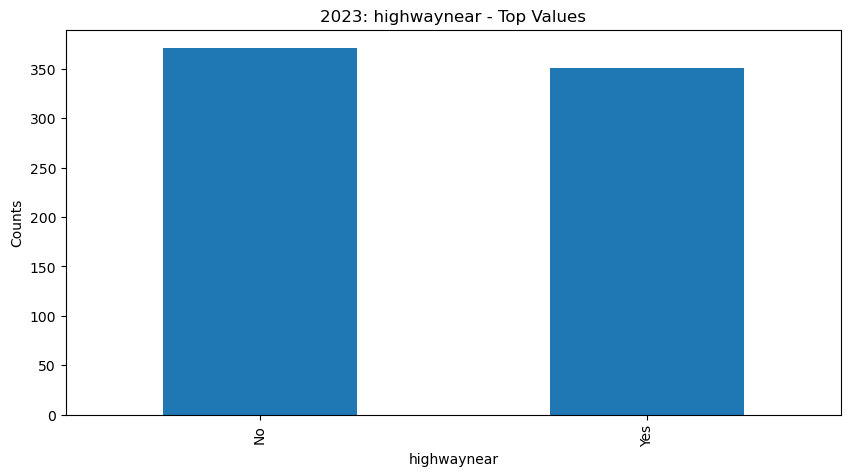

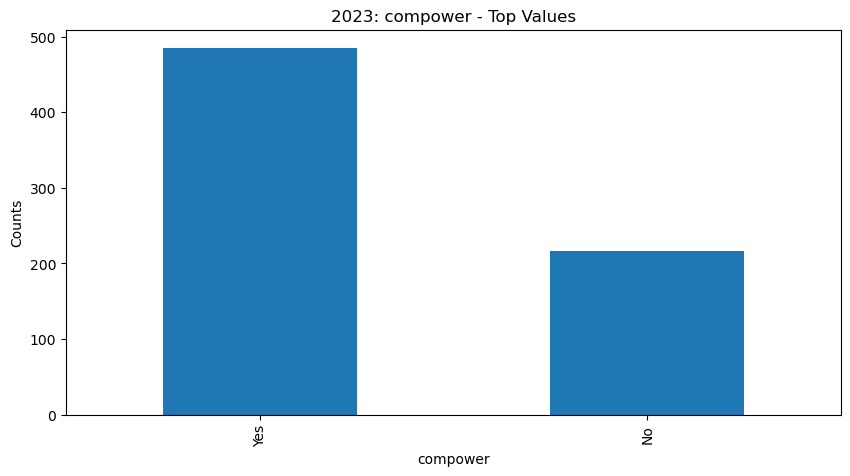

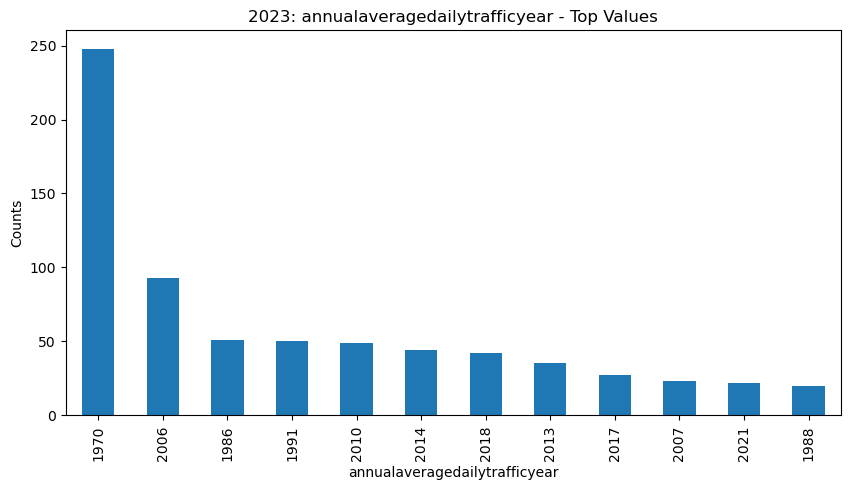

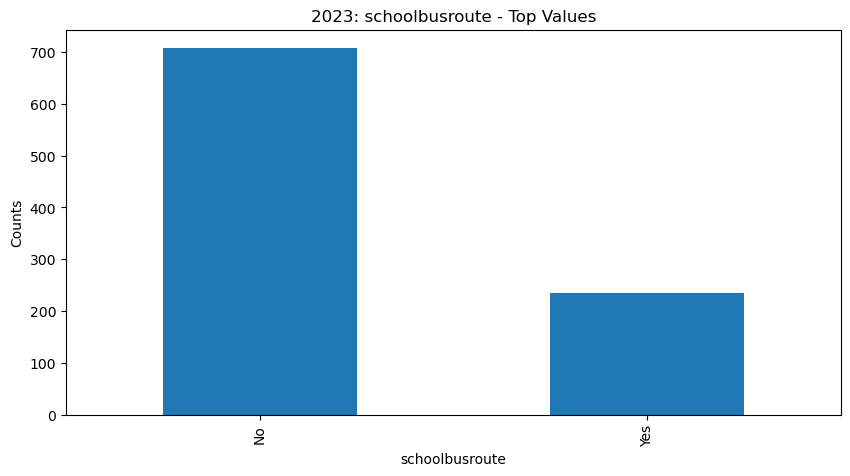

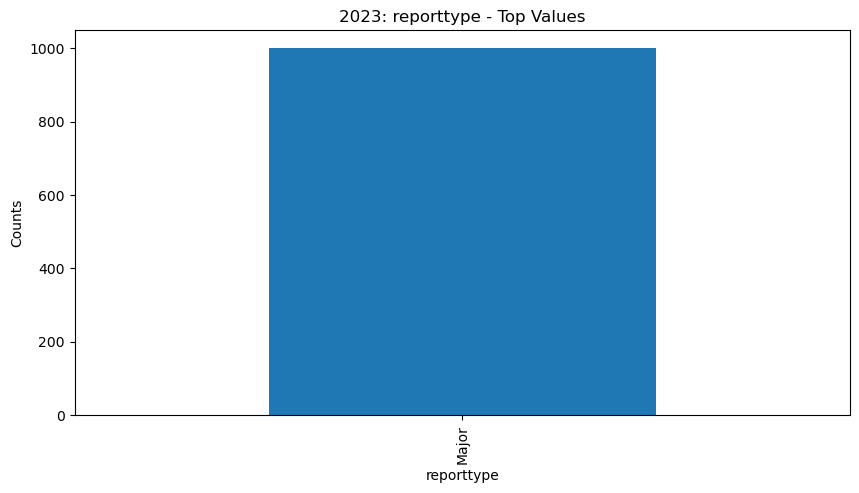

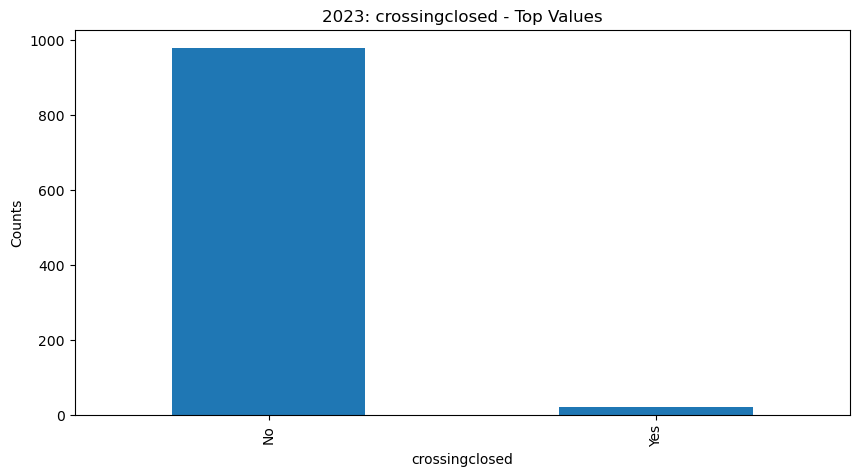

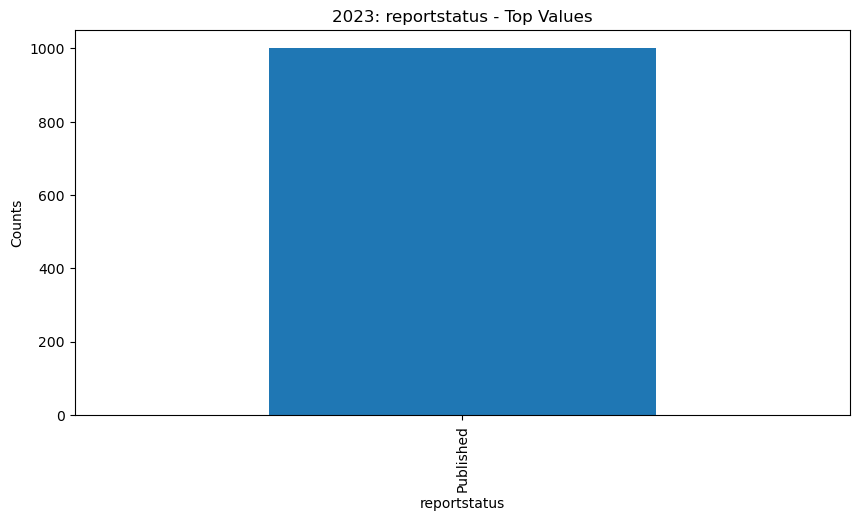

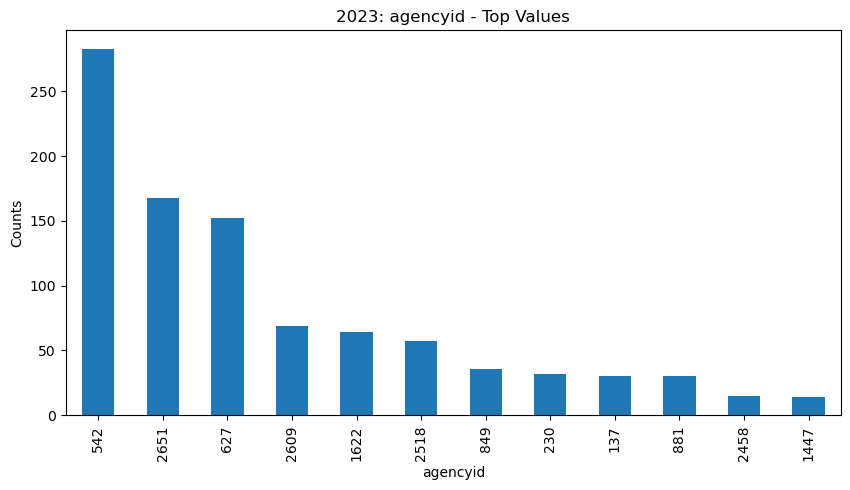

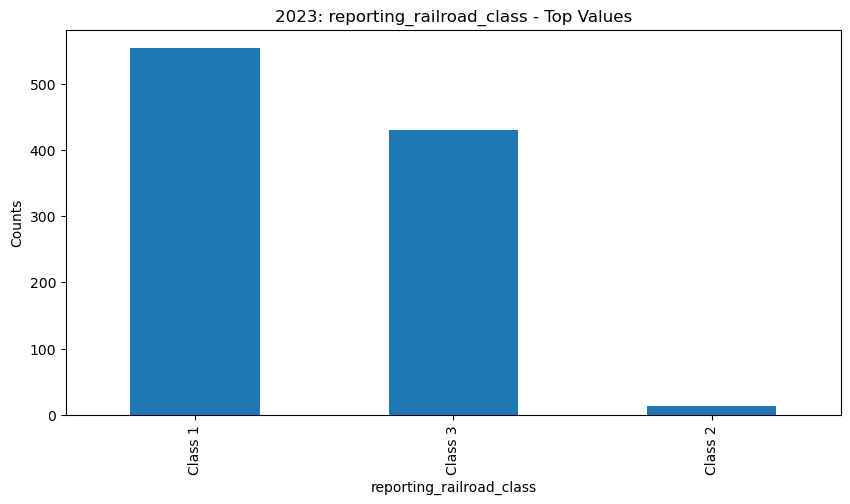

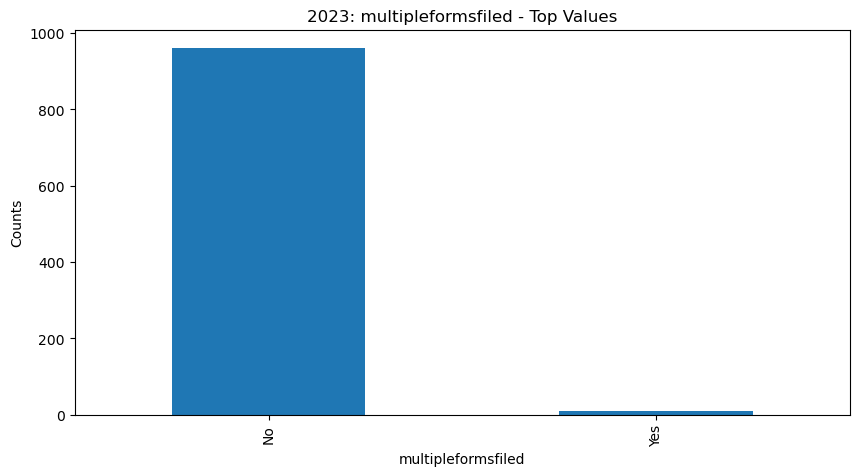

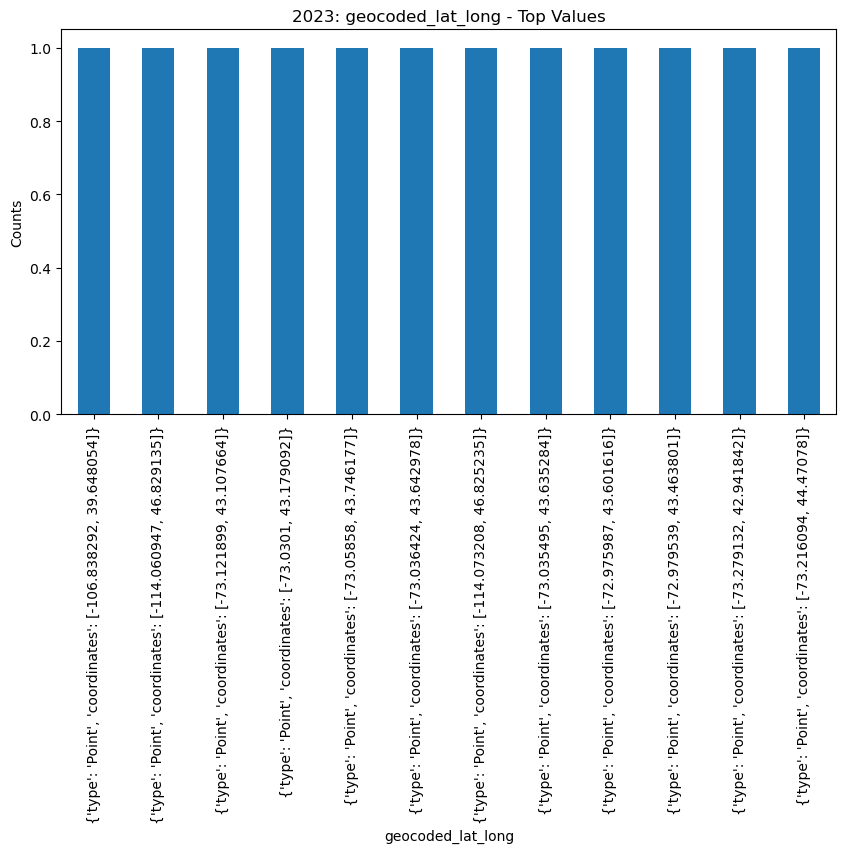

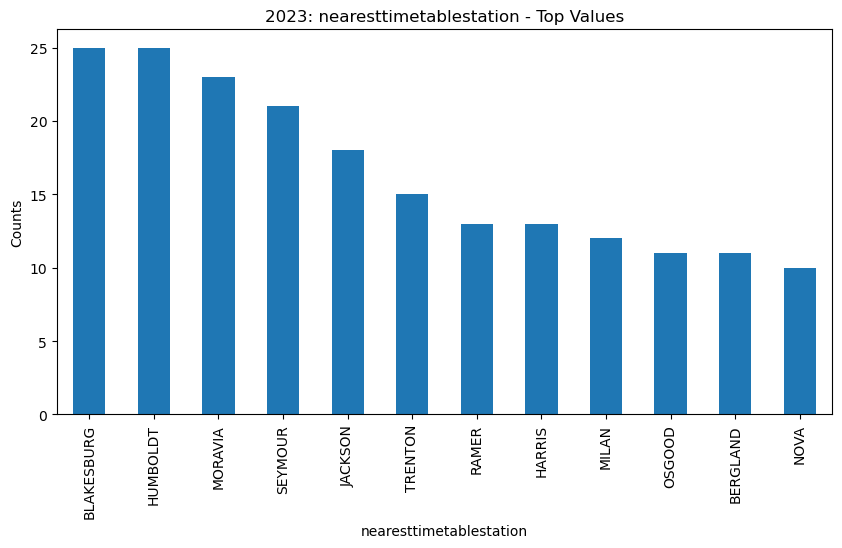

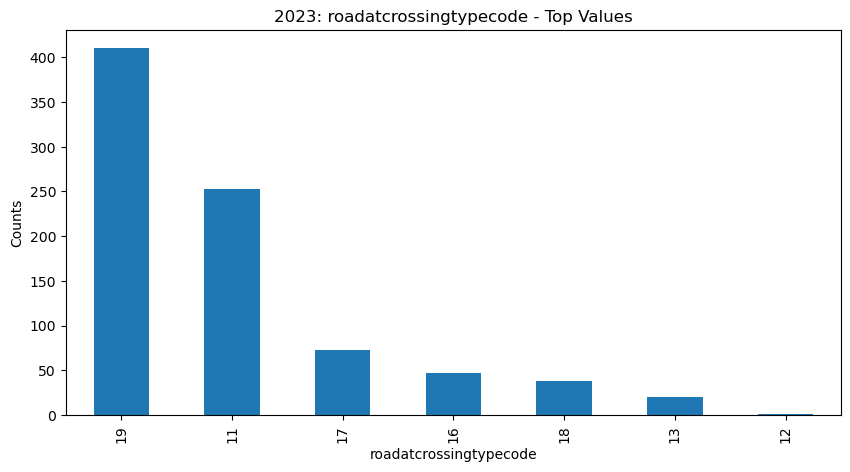

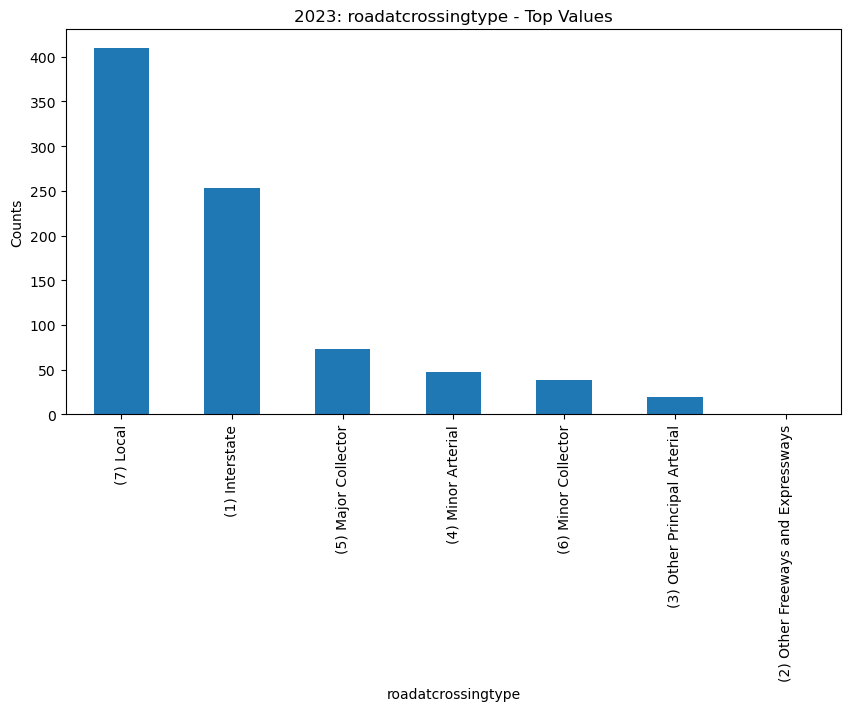

In [8]:
import matplotlib.pyplot as plt

# Iterate over each column in the DataFrame
for column in crossing_inventory_data_clean.columns:
    # Calculate the value counts of the current column
    value_counts = crossing_inventory_data_clean[column].value_counts()

    # Determine the number of unique values
    unique_values = len(value_counts)

    # If there are more than 12 unique values, select the top 12
    if unique_values > 12:
        value_counts = value_counts.head(12)

    # Create a new figure and axis for the histogram
    plt.figure(figsize=(10, 5))

    # Plot the bar chart
    value_counts.plot.bar(title=f'2023: {column} - Top Values')

    # Label the axes
    plt.xlabel(column)
    plt.ylabel('Counts')

    # Show the plot
    plt.show()


In [9]:
form54crossingids = np.load('../Data/Internal/processed/2023form54ids.npz', allow_pickle=True)
print(form54crossingids.files)
form54crossingids['arr_0']

#df = pd.DataFrame(my_array, columns = ['Column_A','Column_B','Column_C'])

form54ids = pd.DataFrame(form54crossingids['arr_0'], columns = ['crossingid'])

print(form54ids)


['arr_0']
     crossingid
0       868284G
1       910400F
2       028672M
3       271925H
4       273145P
...         ...
1363    870492H
1364    225588W
1365    147940X
1366    226610K
1367    807271N

[1368 rows x 1 columns]


In [10]:
crossing_inventory_data_clean['crossingid']

0      253549F
1      448211M
2      375716P
3      375594M
4      375748V
        ...   
995    637727D
996    228433P
997    634909E
998    349389N
999    637731T
Name: crossingid, Length: 1000, dtype: object

In [11]:
# Use isin to check for matches
matches = crossing_inventory_data_clean['crossingid'].isin(form54ids['crossingid'])

# Sum the Boolean values to get the count of matching IDs
count_of_matching_ids = matches.sum()

print(f"Number of matching 'crossingid's: {count_of_matching_ids}")

Number of matching 'crossingid's: 14


In [12]:
len(crossing_inventory_data_clean['crossingid'])

1000